# Genetic Algorithm untuk Alokasi Dana Saham LQ45 dengan Batas Risiko dan Kardinalitas

Notebook ini berisi implementasi lengkap dari fondasi sampai GA, sesuai
[spesifikasi](../docs/superpowers/specs/2026-10-14-optimasi-lq45-metaheuristik-design.md)
dan PDF rencana:

| Bagian | Isi |
|---|---|
| 1 | Setup dan parameter |
| 2 | Data dan kelas `Problem`, `Result` |
| 3 | **Dekoder 2N+1** (kunci + bobot mentah + gen kas → lot yang layak) |
| 4 | **Definisi sisa kas** dalam Rupiah dan rinciannya |
| 5 | **Fungsi objektif**, **kendala risiko (aturan Deb)**, dan `Evaluator` |
| 6 | Pengujian dekoder dan fitness |
| 7 | **Genetic Algorithm** |
| 8 | Verifikasi GA terhadap brute force K = 2 |
| 9 | **Visualisasi proses GA** generasi demi generasi |
| 10 | **Perbandingan setiap K** (2, 3, 5, 7, 10) |
| 11 | **Penjelasan pemilihan saham** dan return yang diharapkan (% dari modal, per saham, data uji) |
| 12 | **Kesimpulan** |

**Cara menjalankan:** *Run All* dari atas ke bawah (sekitar dua menit).

* **Lokal / VS Code:** buka dari root proyek atau folder `notebooks/`; data dibaca dari `data/windows/*.npz`
  (dibuat oleh `python3 src/scrappingdata.py`). Dibutuhkan `numpy`, `pandas`, dan `matplotlib`.
* **Google Colab:** cukup unggah notebook ini. Bila folder data tidak ditemukan, sel pertama mengunduh repositori
  dari GitHub otomatis, jadi tidak ada berkas lain yang perlu diunggah.

Notebook ini **mandiri**: tidak mengimpor `config.py` maupun modul di `src/`.

## Formulasi masalah

**Variabel keputusan:** jumlah lot $n_i \in \mathbb{Z}_{\ge 0}$ untuk tiap saham $i = 1,\dots,N$ ($N = 42$).

Nilai posisi $v_i = 100\, n_i P_i$ ($P_i$ = harga raw per lembar), bobot terhadap dana
$w_i = v_i / D$, dan bobot kas $w_0 = 1 - \sum_i w_i$.

**Fungsi objektif** (dimaksimalkan):

$$R = \sum_{i=1}^{N} w_i \mu_i + w_0\, r_f$$

**Kendala:**

| Kendala | Cara dipenuhi |
|---|---|
| Batas risiko $\sqrt{w^\top \Sigma w} \le \sigma_{\max}$ | **Aturan Deb** (satu-satunya yang bisa dilanggar) |
| Kardinalitas: paling banyak $K$ saham | Dekoder: hanya $K$ kunci terbesar yang dipilih |
| Batas per saham $w_i \le 20\%$ (hanya $K \ge 7$) | Dekoder: potong dan bagikan ulang |
| Lot bulat, $n_i \ge 1$ bila terpilih | Dekoder: pembulatan ke bawah; $n_i = 0$ berarti tidak terpilih |
| Dana tidak terlampaui, $w_0 \ge 0$ | Dekoder: bobot target berjumlah $\le 1$, lalu pembulatan ke bawah |

Kromosom berpanjang **2N+1**: $N$ kunci prioritas, $N$ bobot mentah, dan satu gen kas $g_0 \in [0,1]$.
Gen kas dibutuhkan karena pada $K$ kecil batas risiko sering hanya bisa dipenuhi dengan menahan sebagian dana sebagai kas
(lihat bagian 8).

## 1. Setup dan parameter

In [1]:
import os, sys, time, subprocess
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# --- lokasi data: lokal (root proyek atau notebooks/) maupun Google Colab ---
REPO_URL = "https://github.com/hanscakrawangsa15/OptimasiPortofolioSaham.git"


def cari_root():
    for p in (Path.cwd(), Path.cwd().parent, Path.cwd() / "OptimasiPortofolioSaham"):
        if (p / "data" / "windows" / "kasus_tetap.npz").exists():
            return p
    return None


ROOT = cari_root()
if ROOT is None:                       # mis. Google Colab: hanya notebook ini yang ada -> unduh repo (publik)
    print("Data tidak ditemukan di folder kerja; mengunduh repositori dari GitHub ...")
    tujuan = Path.cwd() / "OptimasiPortofolioSaham"
    if not tujuan.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(tujuan)], check=True)
    ROOT = cari_root()
    assert ROOT is not None, "data/windows/*.npz tidak ada di repositori; jalankan python3 src/scrappingdata.py"

# --- parameter masalah (sesuai PDF rencana) ---
RF            = 0.05                      # return kas / risk-free, 5% per tahun
LOT           = 100                       # 100 lembar per lot
D             = 5_000_000.0               # modal (Rp)
K_LIST        = [2, 3, 5, 7, 10]          # batas jumlah saham
SIGMA_MULT    = 1.5                       # sigma_max = 1,5 x volatilitas portofolio 1/N
CAP           = 0.20                      # 20% per saham ...
CAP_MULAI_K   = 7                         # ... hanya untuk K >= 7
BUDGET        = 20_000                    # anggaran evaluasi per run
HISTORY_STEP  = 200                       # riwayat konvergensi dicatat tiap 200 evaluasi

np.set_printoptions(precision=4, suppress=True, linewidth=120)
print("ROOT =", ROOT)
print(f"D = Rp {D:,.0f} | rf = {RF:.0%} | cap = {CAP:.0%} (K >= {CAP_MULAI_K}) | anggaran = {BUDGET:,} evaluasi")

ROOT = /home/hans/Dokumen/Semester 7 Sisfor/SC/SCProject
D = Rp 5,000,000 | rf = 5% | cap = 20% (K >= 7) | anggaran = 20,000 evaluasi


## 2. Data dan kelas `Problem`

`Problem` hanya berisi data **latih** (μ, Σ, harga beli, σ_max). Return uji sengaja tidak dimasukkan,
supaya algoritma tidak mungkin membocorkan data uji.

In [2]:
@dataclass(frozen=True)
class Problem:
    mu: np.ndarray            # (N,) return tahunan (return sederhana)
    cov: np.ndarray           # (N,N) kovarians tahunan
    price: np.ndarray         # (N,) harga raw (tanpa penyesuaian) pada hari beli
    D: float                  # modal (Rp)
    K: int                    # batas jumlah saham
    sigma_max: float          # batas volatilitas portofolio
    cap: float = 1.0          # batas bobot per saham; 1.0 = tanpa batas (K < 7)
    lot: int = 100
    rf: float = 0.05
    tickers: tuple = ()
    label: str = ""

    @property
    def n(self) -> int:                 # jumlah saham N
        return len(self.mu)

    @property
    def n_genes(self) -> int:           # panjang kromosom = 2N+1
        return 2 * self.n + 1

    @property
    def harga_lot(self) -> np.ndarray:  # biaya 1 lot tiap saham (Rp)
        return self.lot * self.price

    @property
    def layak_beli(self) -> np.ndarray: # saham yang 1 lot-nya muat dalam D x cap
        return self.harga_lot <= self.D * self.cap

    @property
    def vol(self) -> np.ndarray:        # volatilitas tahunan tiap saham
        return np.sqrt(np.diag(self.cov))


@dataclass
class Result:
    lots: np.ndarray          # (N,) lot terbaik (bilangan bulat)
    R: float                  # return ekspektasi (in-sample)
    sigma: float              # volatilitas portofolio
    viol: float               # max(0, sigma - sigma_max); 0 bila layak
    feasible: bool
    history: list             # [(n_eval, R terbaik yang layak)] tiap 200 evaluasi
    n_eval: int
    seconds: float
    seed: int
    x: np.ndarray = None      # kromosom terbaik
    n_eval_best: int = 0      # evaluasi ke-berapa solusi terbaik ditemukan
    status: str = ""
    trace: dict = None        # jejak per generasi (opsional, untuk visualisasi proses GA)


def muat_jendela(nama):
    # Baca data/windows/<nama>.npz (dibuat oleh src/scrappingdata.py): statistik latih, harga beli, sigma_max.
    z = np.load(ROOT / "data" / "windows" / f"{nama}.npz", allow_pickle=False)
    return dict(
        tickers=[str(t) for t in z["tickers"]],
        tanggal_latih_awal=str(z["tanggal_latih_awal"]), tanggal_latih_akhir=str(z["tanggal_latih_akhir"]),
        tanggal_uji_awal=str(z["tanggal_uji_awal"]), tanggal_uji_akhir=str(z["tanggal_uji_akhir"]),
        mu=z["mu"], cov=z["cov"], harga_beli=z["harga_beli"],
        return_uji=z["return_uji"], tanggal_uji=[str(t) for t in z["tanggal_uji"]],   # hanya untuk evaluasi; TIDAK masuk Problem
        vol_benchmark=float(z["vol_benchmark"]),
        sigma_max={float(m): float(v) for m, v in zip(z["sigma_mult"], z["sigma_max"])})


def buat_problem(w, K, D=D, mult=SIGMA_MULT, label=""):
    return Problem(
        mu=w["mu"], cov=w["cov"], price=w["harga_beli"], D=D, K=K,
        sigma_max=w["sigma_max"][mult],
        cap=CAP if K >= CAP_MULAI_K else 1.0,
        lot=LOT, rf=RF, tickers=tuple(t.replace(".JK", "") for t in w["tickers"]), label=label)


# 5 jendela walk-forward + 1 kasus tetap
NAMA_DATA = ["kasus_tetap", "jendela_1", "jendela_2", "jendela_3", "jendela_4", "jendela_5"]
DATA = {nama: muat_jendela(nama) for nama in NAMA_DATA}

w = DATA["kasus_tetap"]
print("Kasus tetap : latih", w["tanggal_latih_awal"], "s.d.", w["tanggal_latih_akhir"],
      "| uji", w["tanggal_uji_awal"], "s.d.", w["tanggal_uji_akhir"])
print("Jumlah saham:", len(w["tickers"]), "| sigma_max (1,5x) =", round(w["sigma_max"][SIGMA_MULT], 4))
print()
print(f"{'Data':<12}{'tgl beli':<12}{'sigma_max':>10}{'vol 1/N':>10}")
for nama, d in DATA.items():
    print(f"{nama:<12}{d['tanggal_latih_akhir']:<12}{d['sigma_max'][SIGMA_MULT]:>10.4f}{d['vol_benchmark']:>10.4f}")

Kasus tetap : latih 2021-11-23 s.d. 2025-09-30 | uji 2025-10-01 s.d. 2026-09-30
Jumlah saham: 42 | sigma_max (1,5x) = 0.239

Data        tgl beli     sigma_max   vol 1/N
kasus_tetap 2025-09-30      0.2390    0.1593
jendela_1   2023-12-14      0.2048    0.1365
jendela_2   2024-07-09      0.1976    0.1318
jendela_3   2025-01-09      0.1962    0.1308
jendela_4   2025-07-31      0.2609    0.1739
jendela_5   2026-02-03      0.2717    0.1811


## 3. Dekoder 2N+1

Dekoder mengubah kromosom $x = [\,k_1..k_N \mid v_1..v_N \mid g_0\,]$ menjadi portofolio **layak** secara deterministik:

1. Saham yang 1 lot-nya melebihi $D \times \text{cap}$ dikeluarkan dari kandidat.
2. Ambil paling banyak $K$ saham dengan kunci $k_i$ terbesar sebagai himpunan terpilih $S$.
3. Kas awal $w_0 = g_0$. Bobot mentah $v_i$ ($i \in S$) dinormalisasi sehingga jumlahnya $1 - w_0$.
4. Bila cap < 100% ($K \ge 7$): potong bobot di atas cap, bagikan kelebihannya ke saham terpilih yang belum penuh
   (ulangi sampai stabil); sisa yang tidak bisa dibagi menjadi kas.
5. Lot: $n_i = \lfloor w_i D / (100 P_i) \rfloor$. Saham dengan $n_i = 0$ dianggap tidak terpilih.
6. Sisa dana ($g_0$, kelebihan cap, sisa pembulatan) menjadi kas.
7. Hitung bobot akhir, σ, dan $R$.

Dengan konstruksi ini kardinalitas, cap, kelipatan lot, dan anggaran **selalu** terpenuhi; hanya batas risiko
yang bisa dilanggar. Versi `decode_batch` memproses seluruh populasi sekaligus (vektor), dan `decode`
hanyalah pembungkus satu baris, jadi keduanya otomatis konsisten.

In [3]:
_EPS = 1e-12


def split(x, N):
    # Pisahkan kromosom menjadi (kunci, bobot mentah, gen kas).
    x = np.asarray(x, float)
    return x[..., :N], x[..., N:2 * N], x[..., 2 * N]


def _cap_redistribute(w, pilih, cap):
    # Langkah 4: potong bobot di atas cap, bagikan kelebihan ke saham terpilih yang belum penuh
    # (sebanding bobotnya), ulangi sampai stabil. Kelebihan yang tak bisa dibagi menjadi kas.
    w = w.copy()
    for _ in range(w.shape[1] + 1):
        lebih = w > cap + _EPS
        if not lebih.any():
            break
        excess = np.where(lebih, w - cap, 0.0).sum(1, keepdims=True)
        w = np.where(lebih, cap, w)
        bebas = pilih & (w < cap - _EPS)
        dasar = np.where(bebas, w, 0.0)
        ds = dasar.sum(1, keepdims=True)
        dasar = np.where(ds > 0, dasar, bebas.astype(float))   # semua bobot bebas nol -> sama rata
        ds = dasar.sum(1, keepdims=True)
        w = w + np.where(ds > 0, excess * dasar / np.where(ds > 0, ds, 1.0), 0.0)
    return np.minimum(w, cap)


def _bobot_target(X, P):
    # Langkah 1-4: kromosom (M, 2N+1) -> (himpunan terpilih (M,N) bool, bobot target (M,N), g0 (M,)).
    X = np.atleast_2d(np.asarray(X, float))
    M, N = X.shape[0], P.n
    if X.shape[1] != P.n_genes:
        raise ValueError(f"lebar kromosom {X.shape[1]} != n_genes {P.n_genes}")
    keys, raw, g0 = split(X, N)
    raw = np.clip(raw, 0.0, 1.0)
    g0 = np.clip(g0, 0.0, 1.0)

    # 1-2. saham terjangkau, lalu K kunci terbesar
    layak = P.layak_beli
    urut = np.argsort(-np.where(layak, keys, -np.inf), axis=1, kind="stable")[:, :P.K]
    pilih = np.zeros((M, N), bool)
    np.put_along_axis(pilih, urut, True, axis=1)
    pilih &= layak

    # 3. bobot awal: (1 - g0) dibagi sebanding bobot mentah (semua nol -> sama rata)
    r = np.where(pilih, raw, 0.0)
    s = r.sum(1, keepdims=True)
    sama = pilih / np.maximum(pilih.sum(1, keepdims=True), 1)
    frac = np.where(s > 0, r / np.where(s > 0, s, 1.0), sama)
    w = (1.0 - g0)[:, None] * frac

    # 4. batas per saham
    if P.cap < 1.0:
        w = _cap_redistribute(w, pilih, P.cap)
    return pilih, w, g0


def decode_batch(X, P):
    # Kromosom (M, 2N+1) -> (lots (M,N) int, bobot akhir (M,N), kas (M,)).
    pilih, w, g0 = _bobot_target(X, P)

    # 5-6. lot bulat, bobot akhir, kas
    lots = np.floor(w * P.D / P.harga_lot).astype(np.int64)
    w_akhir = lots * P.harga_lot / P.D
    kas = np.maximum(1.0 - w_akhir.sum(1), 0.0)
    return lots, w_akhir, kas


def decode(x, P):
    # Satu kromosom -> (lots (N,), bobot (N,), kas).
    lots, w, kas = decode_batch(np.asarray(x, float)[None, :], P)
    return lots[0], w[0], kas[0]


print("dekoder siap")

dekoder siap


## 4. Definisi sisa kas (dalam Rupiah)

Sisa kas akhir adalah dana yang **tidak** menjadi saham:

$$\text{sisa kas} = D - \sum_i n_i \cdot 100 \cdot P_i$$

Nilainya tidak sekadar persentase: ia dinyatakan dalam **Rupiah** dan dirinci menjadi tiga komponen yang
jumlahnya selalu sama dengan sisa kas akhir.

| Komponen | Arti | Rumus |
|---|---|---|
| **Kas sengaja** | porsi $g_0$ yang sengaja ditahan oleh kromosom, biasanya agar batas risiko terpenuhi | $g_0 \cdot D$ |
| **Kelebihan cap / tak teralokasi** | bobot di atas batas 20% (hanya $K \ge 7$) yang tidak bisa dibagikan ke saham lain, atau dana yang tak punya saham tujuan | $D\,(1 - g_0 - \sum w^{\text{target}})$ |
| **Sisa pembulatan lot** | dana yang tidak cukup untuk membeli satu lot tambahan | $D \sum w^{\text{target}} - \text{dana terpakai}$ |

Kas bernilai $r_f$ (5% per tahun), sehingga menahannya tidak gratis: ia menurunkan $R$ bila $\mu$ saham lebih tinggi
dari $r_f$. Karena itu kas yang besar hanya muncul bila memang dibutuhkan untuk memenuhi batas risiko.

**Catatan tafsir:** nilai yang bermakna bagi portofolio adalah **sisa kas akhir** (ditentukan oleh lot yang dibeli).
Pembagian antara kas sengaja dan sisa pembulatan bergantung pada kromosom yang menghasilkannya, karena kromosom berbeda
(dengan $g_0$ berbeda) dapat menghasilkan lot yang sama. Rincian ini adalah rincian menurut kromosom yang ditemukan GA.

In [4]:
def rp(x):
    # Format Rupiah Indonesia, mis. Rp 1.676.000
    return "Rp " + f"{x:,.0f}".replace(",", ".")


def rincian_kas(x, P):
    # Rincian dana dalam Rupiah untuk satu kromosom: dana terpakai, sisa kas akhir, dan tiga komponennya.
    x = np.asarray(x, float)
    pilih, w, g0 = _bobot_target(x[None, :], P)
    lots, _, _ = decode_batch(x[None, :], P)
    terpakai = float((lots[0] * P.harga_lot).sum())
    kas_akhir = P.D - terpakai
    kas_sengaja = float(g0[0] * P.D)
    kas_cap = max(0.0, float(P.D * (1.0 - g0[0] - w[0].sum())))
    kas_bulat = kas_akhir - kas_sengaja - kas_cap                 # sisanya = efek pembulatan lot
    assert kas_bulat >= -1e-6, "sisa pembulatan tidak boleh negatif"
    return dict(modal=P.D, terpakai=terpakai, kas_akhir=kas_akhir, kas_sengaja=kas_sengaja,
                kas_cap=kas_cap, kas_pembulatan=max(kas_bulat, 0.0))


def tabel_portofolio(P, lots, x=None, judul=""):
    # Cetak posisi saham (lot, lembar, harga, nilai Rp, bobot) dan sisa kas dalam Rupiah.
    nilai = lots * P.harga_lot
    idx = np.where(lots > 0)[0]
    idx = idx[np.argsort(-nilai[idx])]
    if judul:
        print(judul)
    print(f"  {'Saham':<7}{'Lot':>5}{'Lembar':>8}{'Harga/lembar':>14}{'Nilai posisi':>16}{'Bobot':>8}")
    for i in idx:
        print(f"  {P.tickers[i]:<7}{lots[i]:>5}{lots[i] * P.lot:>8}{rp(P.price[i]):>14}{rp(nilai[i]):>16}{nilai[i] / P.D:>8.1%}")
    terpakai = nilai.sum()
    kas = P.D - terpakai
    print(f"  {'-' * 58}")
    print(f"  {'Modal':<28}{rp(P.D):>16}")
    print(f"  {'Dana terpakai':<28}{rp(terpakai):>16}{terpakai / P.D:>8.1%}")
    print(f"  {'SISA KAS AKHIR':<28}{rp(kas):>16}{kas / P.D:>8.1%}")
    if x is not None:
        r = rincian_kas(x, P)
        print(f"    - kas sengaja (g0 x D)           {rp(r['kas_sengaja']):>13}")
        print(f"    - kelebihan cap / tak teralokasi {rp(r['kas_cap']):>13}")
        print(f"    - sisa pembulatan lot            {rp(r['kas_pembulatan']):>13}")


# contoh: jendela 3, K = 2, BRIS + ISAT (contoh yang sama dengan bagian 6)
P = buat_problem(DATA["jendela_3"], 2)
i_bris, i_isat = P.tickers.index("BRIS"), P.tickers.index("ISAT")
x = np.zeros(P.n_genes)
x[i_bris] = x[i_isat] = 1.0
x[P.n + i_bris], x[P.n + i_isat] = 0.55, 0.45
x[-1] = 0.30
lots, w, kas = decode(x, P)
tabel_portofolio(P, lots, x, judul="Contoh: jendela 3, K = 2 (g0 = 0,30)")

r = rincian_kas(x, P)
assert abs(r["kas_sengaja"] + r["kas_cap"] + r["kas_pembulatan"] - r["kas_akhir"]) < 1e-6
assert abs(r["kas_akhir"] - (kas * P.D)) < 1e-6 and abs(r["kas_sengaja"] - 1_500_000) < 1e-6
print("\nuji rincian kas: lulus (tiga komponen berjumlah sisa kas akhir)")

# demonstrasi kelebihan cap: K = 7 dengan cap 10% (7 x 10% = 70%), sehingga 30% dana tak bisa dialokasikan
from dataclasses import replace
Pc = replace(buat_problem(DATA["kasus_tetap"], 7), cap=0.10)
rng = np.random.default_rng(5)
xc = rng.random(Pc.n_genes); xc[-1] = 0.0                          # g0 = 0: tidak ada kas sengaja
lc, _, _ = decode(xc, Pc)
tabel_portofolio(Pc, lc, xc, judul="\nDemonstrasi: kasus tetap, K = 7, cap 10%, g0 = 0")
rc = rincian_kas(xc, Pc)
assert abs(rc["kas_sengaja"] + rc["kas_cap"] + rc["kas_pembulatan"] - rc["kas_akhir"]) < 1e-6
assert rc["kas_cap"] > 0.29 * Pc.D, "7 saham x cap 10% hanya menampung 70% dana"
print("\nuji kelebihan cap: lulus (30% dana tak tertampung -> menjadi kas)")

Contoh: jendela 3, K = 2 (g0 = 0,30)
  Saham    Lot  Lembar  Harga/lembar    Nilai posisi   Bobot
  BRIS       7     700      Rp 2.700    Rp 1.890.000   37.8%
  ISAT       6     600      Rp 2.390    Rp 1.434.000   28.7%
  ----------------------------------------------------------
  Modal                           Rp 5.000.000
  Dana terpakai                   Rp 3.324.000   66.5%
  SISA KAS AKHIR                  Rp 1.676.000   33.5%
    - kas sengaja (g0 x D)            Rp 1.500.000
    - kelebihan cap / tak teralokasi          Rp 0
    - sisa pembulatan lot               Rp 176.000

uji rincian kas: lulus (tiga komponen berjumlah sisa kas akhir)

Demonstrasi: kasus tetap, K = 7, cap 10%, g0 = 0
  Saham    Lot  Lembar  Harga/lembar    Nilai posisi   Bobot
  BUKA      29    2900        Rp 170      Rp 493.000    9.9%
  CPIN       1     100      Rp 4.660      Rp 466.000    9.3%
  KLBF       4     400      Rp 1.130      Rp 452.000    9.0%
  JPFA       2     200      Rp 1.960      Rp 392.0

## 5. Fungsi objektif, kendala risiko (aturan Deb), dan `Evaluator`

**Objektif:** $R = w^\top \mu + w_0 r_f$. **Risiko:** $\sigma = \sqrt{w^\top \Sigma w}$.
**Pelanggaran:** $\text{viol} = \max(0,\; \sigma - \sigma_{\max})$.

**Aturan kelayakan Deb** (tanpa koefisien penalti):

* solusi layak (`viol = 0`) selalu lebih baik daripada yang tidak layak;
* dua solusi layak: $R$ lebih besar lebih baik;
* dua solusi tidak layak: `viol` lebih kecil lebih baik.

`Evaluator` adalah **pintu tunggal** evaluasi untuk semua metaheuristik: ia mendekode, menghitung $(R,\sigma,\text{viol})$,
menghitung jumlah evaluasi, menolak melewati anggaran, melacak solusi terbaik menurut Deb, dan mencatat riwayat
konvergensi tiap 200 evaluasi. Satu kromosom = satu evaluasi.

In [5]:
def hitung(lots, w, kas, P):
    # Objektif dan kendala risiko untuk sekumpulan portofolio (batch).
    R = w @ P.mu + kas * P.rf
    var = np.einsum("ij,jk,ik->i", w, P.cov, w)
    sigma = np.sqrt(np.maximum(var, 0.0))
    viol = np.maximum(0.0, sigma - P.sigma_max)
    return R, sigma, viol


# ---------------- aturan Deb ----------------
def deb_urut(R, viol):
    # Indeks dari terbaik ke terburuk: layak dulu (R besar), lalu tak layak (viol kecil).
    layak = viol <= 0.0
    return np.lexsort((-R, np.where(layak, 0.0, viol), ~layak))


def deb_rank(R, viol):
    # Peringkat tiap individu (0 = terbaik).
    urut = deb_urut(R, viol)
    rank = np.empty(len(urut), dtype=np.int64)
    rank[urut] = np.arange(len(urut))
    return rank


def deb_better(a, b):
    # a, b = (R, viol). True bila a lebih baik daripada b menurut aturan Deb.
    (Ra, va), (Rb, vb) = a, b
    if va <= 0 and vb <= 0:
        return Ra > Rb
    if va <= 0:
        return True
    if vb <= 0:
        return False
    return va < vb


class AnggaranHabis(Exception):
    pass


class Evaluator:
    # Pintu tunggal evaluasi: dekode + objektif + risiko + anggaran + solusi terbaik + riwayat.

    def __init__(self, P, budget=BUDGET, step=HISTORY_STEP):
        self.P, self.budget, self.step = P, budget, step
        self.n_eval = 0
        self.n_eval_best = 0
        self.best = None                 # dict: x, lots, R, sigma, viol
        self.history = []                # [(n_eval, R terbaik yang layak atau nan)]

    def evaluate(self, X):
        X = np.atleast_2d(np.asarray(X, float))
        if X.shape[1] != self.P.n_genes:
            raise ValueError(f"lebar kromosom {X.shape[1]} != n_genes {self.P.n_genes}")
        if self.n_eval + len(X) > self.budget:
            raise AnggaranHabis(f"{self.n_eval} + {len(X)} > anggaran {self.budget}")
        hasil_R, hasil_s, hasil_v = [], [], []
        i = 0
        while i < len(X):                                   # pecah di kelipatan `step` agar riwayat tepat
            batas = self.step - (self.n_eval % self.step)
            chunk = X[i:i + batas]
            lots, w, kas = decode_batch(chunk, self.P)
            R, s, v = hitung(lots, w, kas, self.P)
            j = deb_urut(R, v)[0]
            cand = (R[j], v[j])
            if self.best is None or deb_better(cand, (self.best["R"], self.best["viol"])):
                self.best = dict(x=chunk[j].copy(), lots=lots[j].copy(), R=R[j], sigma=s[j], viol=v[j])
                self.n_eval_best = self.n_eval + j + 1
            self.n_eval += len(chunk)
            if self.n_eval % self.step == 0:
                b = self.best
                self.history.append((self.n_eval, b["R"] if b["viol"] <= 0 else np.nan))
            hasil_R.append(R); hasil_s.append(s); hasil_v.append(v)
            i += len(chunk)
        return np.concatenate(hasil_R), np.concatenate(hasil_s), np.concatenate(hasil_v)

    def hasil(self, seed, seconds):
        b = self.best
        return Result(lots=b["lots"], R=float(b["R"]), sigma=float(b["sigma"]), viol=float(b["viol"]),
                      feasible=bool(b["viol"] <= 0), history=list(self.history), n_eval=self.n_eval,
                      seconds=seconds, seed=seed, x=b["x"], n_eval_best=self.n_eval_best)


print("fitness dan Evaluator siap")

fitness dan Evaluator siap


## 6. Pengujian dekoder dan fitness

Semua uji memakai `assert`: bila ada yang gagal, sel berhenti dengan galat.

1. **Invarian dekoder** pada 10.000 kromosom acak untuk tiap $K$: jumlah saham ≤ $K$, bobot ≤ cap, lot bulat,
   dana terpakai ≤ $D$, kas ≥ 0, dan saham yang tidak terjangkau tidak pernah terpilih.
2. **Dekoder vektor = dekoder referensi** yang ditulis terpisah dengan loop biasa.
3. **Kasus degenerat dan gen kas:** $g_0 = 1$ semua kas; K = 1 menghabiskan dana sampai sisa kurang dari satu lot.
4. **Aturan Deb** dan **`Evaluator`** (anggaran, riwayat, lebar kromosom).
5. **Contoh nyata** dari jendela 3.

In [6]:
def acak_kromosom(P, rng, m, g0_maks=1.0):
    X = rng.random((m, P.n_genes))
    X[:, -1] = rng.uniform(0.0, g0_maks, m)
    return X


# ---------- 1. invarian dekoder ----------
rng = np.random.default_rng(12345)
for nama in ["kasus_tetap", "jendela_3"]:
    for K in K_LIST:
        P = buat_problem(DATA[nama], K)
        X = acak_kromosom(P, rng, 10_000)
        lots, w, kas = decode_batch(X, P)
        biaya = P.harga_lot
        assert lots.dtype.kind == "i" and (lots >= 0).all(), "lot harus bilangan bulat >= 0"
        assert ((lots > 0).sum(1) <= K).all(), "jumlah saham melebihi K"
        assert (w <= P.cap + 1e-9).all(), "bobot melebihi cap"
        assert ((lots * biaya).sum(1) <= P.D * (1 + 1e-12)).all(), "dana terpakai melebihi D"
        assert (kas >= 0).all() and np.allclose(w.sum(1) + kas, 1.0), "bobot + kas harus = 1"
        assert (lots[:, ~P.layak_beli] == 0).all(), "saham tak terjangkau terpilih"
print("1. invarian dekoder: lulus (2 data x 5 nilai K x 10.000 kromosom)")


# ---------- 2. dekoder referensi (loop biasa, ditulis terpisah) ----------
def decode_referensi(x, P):
    N = P.n
    keys, raw, g0 = x[:N], np.clip(x[N:2 * N], 0, 1), min(max(x[2 * N], 0.0), 1.0)
    kandidat = [i for i in range(N) if P.harga_lot[i] <= P.D * P.cap]
    kandidat.sort(key=lambda i: (-keys[i], i))
    S = kandidat[:P.K]
    w = np.zeros(N)
    if S:
        tot = sum(raw[i] for i in S)
        for i in S:
            w[i] = (1 - g0) * (raw[i] / tot if tot > 0 else 1.0 / len(S))
    if P.cap < 1.0:
        for _ in range(N + 1):
            lebih = [i for i in S if w[i] > P.cap + _EPS]
            if not lebih:
                break
            excess = sum(w[i] - P.cap for i in lebih)
            for i in lebih:
                w[i] = P.cap
            bebas = [i for i in S if w[i] < P.cap - _EPS]
            if not bebas:
                continue
            dasar = [w[i] for i in bebas]
            if sum(dasar) <= 0:
                dasar = [1.0] * len(bebas)
            for i, b in zip(bebas, dasar):
                w[i] += excess * b / sum(dasar)
    lots = np.array([int(np.floor(w[i] * P.D / P.harga_lot[i])) for i in range(N)])
    return lots


rng = np.random.default_rng(7)
for K in K_LIST:
    P = buat_problem(DATA["jendela_3"], K)
    X = acak_kromosom(P, rng, 1500)
    lots_v, _, _ = decode_batch(X, P)
    for x, lv in zip(X, lots_v):
        assert (decode_referensi(x, P) == lv).all(), f"beda dari referensi (K={K})"
    lots_1, _, _ = decode(X[0], P)
    assert (lots_1 == lots_v[0]).all()
print("2. dekoder vektor = dekoder referensi: lulus (5 nilai K x 1.500 kromosom)")


# ---------- 3. kasus degenerat dan gen kas ----------
P = buat_problem(DATA["kasus_tetap"], 2)
x = np.zeros(P.n_genes); x[-1] = 1.0                       # g0 = 1 -> semua kas
lots, w, kas = decode(x, P)
R, s, v = hitung(lots[None], w[None], np.array([kas]), P)
assert lots.sum() == 0 and abs(kas - 1) < 1e-12 and abs(R[0] - RF) < 1e-12 and s[0] == 0 and v[0] == 0
print("3a. g0 = 1: semua kas, R = r_f, sigma = 0, layak")

P1 = buat_problem(DATA["kasus_tetap"], 1)
rng = np.random.default_rng(3)
for _ in range(200):
    x = rng.random(P1.n_genes); x[-1] = 0.0                # g0 = 0 setara versi 2N
    lots, w, kas = decode(x, P1)
    assert (lots > 0).sum() == 1
    i = int(np.argmax(lots))
    assert kas < P1.harga_lot[i] / P1.D + 1e-12, "sisa dana harus kurang dari satu lot"
print("3b. K = 1, g0 = 0: satu saham, sisa dana kurang dari satu lot")


# ---------- 4. aturan Deb dan Evaluator ----------
R_ = np.array([0.30, 0.20, 0.50, 0.40, 0.10])
v_ = np.array([0.0, 0.0, 0.05, 0.01, 0.0])
assert list(deb_urut(R_, v_)) == [0, 1, 4, 3, 2]            # layak (R turun), lalu tak layak (viol naik)
assert deb_better((0.2, 0.0), (0.9, 0.01)) and not deb_better((0.9, 0.01), (0.2, 0.0))
assert deb_better((0.3, 0.0), (0.2, 0.0)) and deb_better((0.1, 0.01), (0.9, 0.05))
assert list(deb_rank(R_, v_)) == [0, 1, 4, 3, 2]

P = buat_problem(DATA["kasus_tetap"], 5)
ev = Evaluator(P, budget=1000)
rng = np.random.default_rng(1)
ev.evaluate(acak_kromosom(P, rng, 450))
ev.evaluate(acak_kromosom(P, rng, 150))
assert ev.n_eval == 600 and [h[0] for h in ev.history] == [200, 400, 600]
bests = [h[1] for h in ev.history if not np.isnan(h[1])]
assert all(b2 >= b1 - 1e-12 for b1, b2 in zip(bests, bests[1:])), "R terbaik yang layak tidak boleh turun"
try:
    ev.evaluate(acak_kromosom(P, rng, 401)); raise SystemExit("seharusnya AnggaranHabis")
except AnggaranHabis:
    pass
try:
    ev.evaluate(np.zeros((1, P.n_genes - 1))); raise SystemExit("seharusnya ValueError")
except ValueError:
    pass
print("4. aturan Deb dan Evaluator (anggaran, riwayat tiap 200, lebar kromosom): lulus")

1. invarian dekoder: lulus (2 data x 5 nilai K x 10.000 kromosom)


2. dekoder vektor = dekoder referensi: lulus (5 nilai K x 1.500 kromosom)
3a. g0 = 1: semua kas, R = r_f, sigma = 0, layak
3b. K = 1, g0 = 0: satu saham, sisa dana kurang dari satu lot
4. aturan Deb dan Evaluator (anggaran, riwayat tiap 200, lebar kromosom): lulus


In [7]:
# ---------- 5. contoh nyata: jendela 3, K = 2 (BRIS + ISAT) ----------
P = buat_problem(DATA["jendela_3"], 2)
i_bris, i_isat = P.tickers.index("BRIS"), P.tickers.index("ISAT")

x = np.zeros(P.n_genes)
x[i_bris] = x[i_isat] = 1.0                      # kunci: BRIS dan ISAT teratas
x[P.n + i_bris], x[P.n + i_isat] = 0.55, 0.45    # bobot mentah 0,55 : 0,45
x[-1] = 0.30                                      # g0: 30% kas awal

lots, w, kas = decode(x, P)
R, s, v = hitung(lots[None], w[None], np.array([kas]), P)
print(f"BRIS: 1 lot = Rp {P.harga_lot[i_bris]:,.0f} | ISAT: 1 lot = Rp {P.harga_lot[i_isat]:,.0f}")
print(f"lot       : BRIS {lots[i_bris]}, ISAT {lots[i_isat]}")
print(f"bobot     : BRIS {w[i_bris]:.3f}, ISAT {w[i_isat]:.3f} | kas akhir {kas:.3f}")
print(f"sigma     : {s[0]:.4f}  (batas {P.sigma_max:.4f})  -> layak: {v[0] == 0}")
print(f"R         : {R[0]:.4f}")
assert (lots[i_bris], lots[i_isat]) == (7, 6) and v[0] == 0 and abs(R[0] - 0.2817) < 5e-4
print("5. contoh nyata: lulus (7 dan 6 lot, kas 33,5%, sigma 0,1952, R 0,2817)")

# Gen kas sebagai tuas risiko: pasangan yang sama, hanya g0 yang diubah
print(f"\n{'g0':>5}{'lot BRIS':>10}{'lot ISAT':>10}{'kas akhir':>11}{'sigma':>9}{'layak':>8}{'R':>9}")
for g in [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]:
    xg = x.copy(); xg[-1] = g
    l, ww, k = decode(xg, P)
    Rg, sg, vg = hitung(l[None], ww[None], np.array([k]), P)
    print(f"{g:>5.2f}{l[i_bris]:>10}{l[i_isat]:>10}{k:>11.3f}{sg[0]:>9.4f}{'ya' if vg[0] == 0 else 'TIDAK':>8}{Rg[0]:>9.4f}")

BRIS: 1 lot = Rp 270,000 | ISAT: 1 lot = Rp 239,000
lot       : BRIS 7, ISAT 6
bobot     : BRIS 0.378, ISAT 0.287 | kas akhir 0.335
sigma     : 0.1952  (batas 0.1962)  -> layak: True
R         : 0.2817
5. contoh nyata: lulus (7 dan 6 lot, kas 33,5%, sigma 0,1952, R 0,2817)

   g0  lot BRIS  lot ISAT  kas akhir    sigma   layak        R
 0.00        10         9      0.030   0.2834   TIDAK   0.3866
 0.10         9         8      0.132   0.2540   TIDAK   0.3516
 0.20         8         7      0.233   0.2246   TIDAK   0.3166
 0.30         7         6      0.335   0.1952      ya   0.2817
 0.40         6         5      0.437   0.1659      ya   0.2467
 0.50         5         4      0.539   0.1365      ya   0.2117


## 7. Genetic Algorithm

Parameter sesuai PDF: populasi 100, 200 generasi (anggaran 20.000 evaluasi), turnamen $k=3$, SBX ($p=0{,}9$, $\eta=15$),
mutasi Gaussian ($1/N$ per gen, $\sigma=0{,}1$), elitisme 2, dan perbandingan individu dengan aturan Deb.

* **Representasi:** kromosom 2N+1 di $[0,1]$; dekoder bersama (bagian 3).
* **Inisialisasi:** acak, dengan sebagian (10 individu) disemai dari heuristik top-K (skor $(\mu_i - r_f)/\sigma_i$) dan
  $g_0$ rendah, agar tidak mulai dari nol.
* **Mutasi:** Gaussian pada bobot mentah **dan** $g_0$; mutasi *swap* pada kunci menukar prioritas satu saham terpilih
  dengan satu saham di luar (probabilitas per individu `p_swap`, nilai awal 0,2; akan ditala di Fase 1).
* **Anggaran:** populasi awal 100 evaluasi + 199 generasi × 100 = **20.000**. Elit disalin dari generasi sebelumnya
  (tanpa evaluasi ulang) menggantikan dua anak terburuk.
* **Reprodusibel:** satu `default_rng(seed)` per run.

In [8]:
GA_PARAM = dict(pop=100, turnamen=3, p_sbx=0.9, eta=15.0, sigma_mut=0.1,
                p_swap=0.2, elitisme=2, n_seed=10)


def init_population(P, rng, n, n_seed=0):
    # Populasi awal (n, 2N+1): acak seragam, g0 di [0; 0,5]; n_seed baris pertama disemai top-K.
    N = P.n
    X = np.empty((n, P.n_genes))
    X[:, :N] = rng.random((n, N))
    X[:, N:2 * N] = rng.random((n, N))
    X[:, 2 * N] = rng.uniform(0.0, 0.5, n)
    skor = (P.mu - P.rf) / P.vol                                  # heuristik: return lebih per unit risiko
    skor = (skor - skor.min()) / (skor.max() - skor.min() + 1e-12)
    for i in range(min(n_seed, n)):
        X[i, :N] = np.clip(skor + rng.normal(0.0, 0.05, N), 0.0, 1.0)
        X[i, N:2 * N] = rng.uniform(0.3, 1.0, N)
        X[i, 2 * N] = rng.uniform(0.0, 0.1)
    return X


def turnamen(rank, rng, n, k):
    # Seleksi turnamen ukuran k berdasarkan peringkat Deb (rank kecil = baik).
    cand = rng.integers(0, len(rank), size=(n, k))
    return cand[np.arange(n), np.argmin(rank[cand], axis=1)]


def sbx(p1, p2, eta, rng):
    u = rng.random(p1.shape)
    beta = np.where(u <= 0.5, (2 * u) ** (1 / (eta + 1)), (1 / (2 * (1 - u))) ** (1 / (eta + 1)))
    return (0.5 * ((1 + beta) * p1 + (1 - beta) * p2),
            0.5 * ((1 - beta) * p1 + (1 + beta) * p2))


def mutasi_swap(kids, P, p_swap, rng):
    # Tukar kunci satu saham terpilih dengan satu saham terjangkau di luar himpunan terpilih.
    N, K = P.n, P.K
    kand = np.where(P.layak_beli)[0]
    if len(kand) <= K:
        return
    for i in np.where(rng.random(len(kids)) < p_swap)[0]:
        urut = kand[np.argsort(-kids[i, kand], kind="stable")]
        a, b = urut[rng.integers(0, K)], urut[rng.integers(K, len(urut))]
        kids[i, a], kids[i, b] = kids[i, b], kids[i, a]


def ga_run(P, budget=BUDGET, seed=0, trace=False, **kw):
    # Satu run GA. trace=True menyimpan keadaan populasi tiap generasi (untuk visualisasi proses GA).
    prm = {**GA_PARAM, **kw}
    rng = np.random.default_rng(seed)
    ev = Evaluator(P, budget)
    t0 = time.perf_counter()
    n, N, E = prm["pop"], P.n, prm["elitisme"]
    rec = {k: [] for k in ("R", "sigma", "viol", "g0", "kas", "n_unik", "lots_terbaik")} if trace else None

    def catat(pop, R, s, v):
        if rec is None:
            return
        lots, _, kas = decode_batch(pop, P)
        rec["R"].append(R.copy()); rec["sigma"].append(s.copy()); rec["viol"].append(v.copy())
        rec["g0"].append(np.clip(pop[:, -1], 0.0, 1.0)); rec["kas"].append(kas)
        rec["n_unik"].append(len({tuple(np.where(l > 0)[0]) for l in lots}))
        rec["lots_terbaik"].append(lots[deb_urut(R, v)[0]])

    pop = init_population(P, rng, n, prm["n_seed"])
    R, s, v = ev.evaluate(pop)
    catat(pop, R, s, v)

    while ev.n_eval + n <= budget:
        rank = deb_rank(R, v)
        elit = np.argsort(rank)[:E]                              # elit generasi ini
        par = pop[turnamen(rank, rng, n, prm["turnamen"])]
        p1, p2 = par[0::2], par[1::2]
        c1, c2 = sbx(p1, p2, prm["eta"], rng)
        pakai = (rng.random(len(p1)) < prm["p_sbx"])[:, None]    # SBX hanya pada sebagian pasangan
        kids = np.empty_like(pop)
        kids[0::2], kids[1::2] = np.where(pakai, c1, p1), np.where(pakai, c2, p2)

        mask = rng.random((n, N + 1)) < 1.0 / N                  # mutasi Gaussian: bobot mentah dan g0
        kids[:, N:] += mask * rng.normal(0.0, prm["sigma_mut"], (n, N + 1))
        mutasi_swap(kids, P, prm["p_swap"], rng)
        kids = np.clip(kids, 0.0, 1.0)

        Rk, sk, vk = ev.evaluate(kids)
        terburuk = deb_urut(Rk, vk)[::-1][:E]                    # elitisme: elit menggantikan anak terburuk
        kids[terburuk], Rk[terburuk], sk[terburuk], vk[terburuk] = pop[elit], R[elit], s[elit], v[elit]
        pop, R, s, v = kids, Rk, sk, vk
        catat(pop, R, s, v)

    hasil = ev.hasil(seed, time.perf_counter() - t0)
    if trace:
        hasil.trace = {k: np.array(val) for k, val in rec.items()}
    return hasil


# uji cepat: reprodusibel, anggaran tepat, hasil layak
P = buat_problem(DATA["kasus_tetap"], 7)
a, b, c = ga_run(P, seed=11), ga_run(P, seed=11), ga_run(P, seed=12)
assert a.n_eval == BUDGET and np.array_equal(a.lots, b.lots) and a.R == b.R, "seed sama harus identik"
assert not np.array_equal(a.x, c.x), "seed beda harus beda"
assert len(a.history) == BUDGET // HISTORY_STEP
t = ga_run(P, seed=11, trace=True)
assert t.R == a.R and np.array_equal(t.lots, a.lots), "trace tidak boleh mengubah hasil"
assert t.trace["R"].shape == (BUDGET // GA_PARAM["pop"], GA_PARAM["pop"])
print(f"GA K=7 kasus tetap: R = {a.R:.4f}, sigma = {a.sigma:.4f} (batas {P.sigma_max:.4f}), "
      f"layak = {a.feasible}, {a.n_eval:,} evaluasi, {a.seconds:.2f} detik")

GA K=7 kasus tetap: R = 0.3372, sigma = 0.2380 (batas 0.2390), layak = True, 20,000 evaluasi, 0.25 detik


## 8. Verifikasi GA terhadap brute force K = 2

Untuk $K \le 2$ ruang pencarian kecil, sehingga **optimum sejati** dapat dihitung dengan mengenumerasi semua saham
tunggal dan semua pasangan saham beserta semua kombinasi lot (≈ 550 ribu kombinasi pada kasus tetap).
Brute force ini memakai model yang sama dengan GA: lot bulat, posisi minimum 1 lot, kas **bebas** (bernilai $r_f$),
dan batas risiko. GA harus menemukan (atau sangat mendekati) optimum ini.

Brute force juga menjawab pertanyaan penting: *apa yang hilang bila kas tidak boleh ditahan sengaja?* Tiga aturan kas
dibandingkan: kas bebas (model PDF), kas ≤ 5% (kendala keras), dan kas hanya dari pembulatan (setara vektor 2N tanpa $g_0$).

In [9]:
def brute_force_k2(P):
    # Optimum sejati untuk K <= 2: semua saham tunggal dan pasangan, semua kombinasi lot (n_i >= 1).
    # Mengembalikan dict {aturan_kas: (R, {saham: lot}, kas)}.
    mu, cov, c, D, rf = P.mu, P.cov, P.harga_lot, P.D, P.rf
    N = P.n
    terbaik = {"kas bebas": (-9.0, None, None), "kas <= 5%": (-9.0, None, None),
               "kas hanya dari pembulatan": (-9.0, None, None)}

    def catat(nama, R, lot, kas):
        if R > terbaik[nama][0]:
            terbaik[nama] = (float(R), lot, float(kas))

    def aturan(layak, kas, biaya_min):
        return {"kas bebas": layak, "kas <= 5%": layak & (kas <= 0.05),
                "kas hanya dari pembulatan": layak & (kas * D < biaya_min)}

    for i in range(N):
        n1 = np.arange(1, int(D // c[i]) + 1)
        w1 = n1 * c[i] / D
        kas = 1 - w1
        sigma = w1 * np.sqrt(cov[i, i])
        R = w1 * mu[i] + kas * rf
        for nama, m in aturan(sigma <= P.sigma_max, kas, c[i]).items():
            if m.any():
                k = np.argmax(np.where(m, R, -9)); catat(nama, R[k], {P.tickers[i]: int(n1[k])}, kas[k])
        for j in range(i + 1, N):
            a = np.arange(1, int(D // c[i]) + 1)[:, None]
            b = np.arange(1, int(D // c[j]) + 1)[None, :]
            ok = a * c[i] + b * c[j] <= D
            w1, w2 = a * c[i] / D, b * c[j] / D
            kas = 1 - w1 - w2
            var = w1 ** 2 * cov[i, i] + w2 ** 2 * cov[j, j] + 2 * w1 * w2 * cov[i, j]
            R = w1 * mu[i] + w2 * mu[j] + kas * rf
            layak = ok & (np.sqrt(var) <= P.sigma_max)
            for nama, m in aturan(layak, kas, c[i] + c[j]).items():
                if m.any():
                    idx = np.unravel_index(np.argmax(np.where(m, R, -9)), R.shape)
                    catat(nama, R[idx], {P.tickers[i]: int(a[idx[0], 0]), P.tickers[j]: int(b[0, idx[1]])}, kas[idx])
    return terbaik


t0 = time.perf_counter()
BF = {nama: brute_force_k2(buat_problem(DATA[nama], 2)) for nama in ["kasus_tetap", "jendela_3", "jendela_5"]}
print(f"brute force selesai dalam {time.perf_counter() - t0:.1f} detik\n")
print(f"{'data':<13}{'aturan kas':<28}{'R*':>8}{'kas':>7}   portofolio optimum")
for nama, hasil in BF.items():
    for aturan_kas, (R, lot, kas) in hasil.items():
        print(f"{nama:<13}{aturan_kas:<28}{R:>8.4f}{kas:>7.3f}   {lot}")
    print()

brute force selesai dalam 0.2 detik

data         aturan kas                        R*    kas   portofolio optimum
kasus_tetap  kas bebas                     0.2966  0.242   {'BRPT': 4, 'ITMG': 1}
kasus_tetap  kas <= 5%                     0.2115  0.014   {'BMRI': 6, 'ITMG': 1}
kasus_tetap  kas hanya dari pembulatan     0.2966  0.242   {'BRPT': 4, 'ITMG': 1}

jendela_3    kas bebas                     0.2817  0.335   {'BRIS': 7, 'ISAT': 6}
jendela_3    kas <= 5%                     0.2067  0.018   {'INDF': 4, 'ISAT': 8}
jendela_3    kas hanya dari pembulatan     0.2407  0.172   {'BRIS': 7, 'INDF': 3}

jendela_5    kas bebas                     0.5114  0.038   {'ANTM': 4, 'PGAS': 15}
jendela_5    kas <= 5%                     0.5114  0.038   {'ANTM': 4, 'PGAS': 15}
jendela_5    kas hanya dari pembulatan     0.5114  0.038   {'ANTM': 4, 'PGAS': 15}



In [10]:
# GA (30 seed, anggaran 20.000) vs optimum brute force dengan kas bebas
N_SEED = 30
hasil_k2 = {}
print(f"{'data':<13}{'R* (brute force)':>18}{'R GA terbaik':>14}{'R GA median':>13}{'R GA minimum':>14}{'gap median':>12}{'tepat optimum':>15}{'sukses gap<=1%':>16}{'layak':>7}{'detik/run':>11}")
for nama in ["kasus_tetap", "jendela_3", "jendela_5"]:
    P = buat_problem(DATA[nama], 2)
    runs = [ga_run(P, seed=s) for s in range(N_SEED)]
    hasil_k2[nama] = runs
    Rs = np.array([r.R if r.feasible else np.nan for r in runs])    # R hanya bermakna untuk solusi layak
    Rstar = BF[nama]["kas bebas"][0]
    layak = np.mean([r.feasible for r in runs])
    cocok = np.mean(np.nan_to_num(Rs, nan=-9) >= Rstar - 1e-9)
    gap = (Rstar - np.nanmedian(Rs)) / Rstar
    sukses = np.mean(np.nan_to_num(Rs, nan=-9) >= Rstar * (1 - 0.01))      # success rate PDF: gap <= 1%
    print(f"{nama:<13}{Rstar:>18.4f}{np.nanmax(Rs):>14.4f}{np.nanmedian(Rs):>13.4f}{np.nanmin(Rs):>14.4f}{gap:>11.2%}{cocok:>14.0%}{sukses:>16.0%}{layak:>7.0%}"
          f"{np.mean([r.seconds for r in runs]):>11.2f}")
    assert np.nanmax(Rs) <= Rstar + 1e-9, "GA tidak boleh melampaui optimum sejati (indikasi galat)"

data           R* (brute force)  R GA terbaik  R GA median  R GA minimum  gap median  tepat optimum  sukses gap<=1%  layak  detik/run


kasus_tetap              0.2966        0.2966       0.2963        0.2484      0.10%           37%             73%   100%       0.21


jendela_3                0.2817        0.2817       0.2817        0.2342      0.00%           60%             60%   100%       0.21


jendela_5                0.5114        0.5114       0.5114        0.5002      0.00%           70%             97%   100%       0.21


In [11]:
print("Catatan: GA menemukan optimum sejati pada sebagian seed saja. Seed yang terjebak berhenti jauh di bawah optimum")
print("(batas bawah pita pada grafik di bawah), sehingga median GA hampir optimum tetapi variansi antar seed besar.")
print("Ini bahan penalaan Fase 1 (ukuran populasi, p_swap, n_seed) dan alasan memakai 30 seed per masalah.")

Catatan: GA menemukan optimum sejati pada sebagian seed saja. Seed yang terjebak berhenti jauh di bawah optimum
(batas bawah pita pada grafik di bawah), sehingga median GA hampir optimum tetapi variansi antar seed besar.
Ini bahan penalaan Fase 1 (ukuran populasi, p_swap, n_seed) dan alasan memakai 30 seed per masalah.


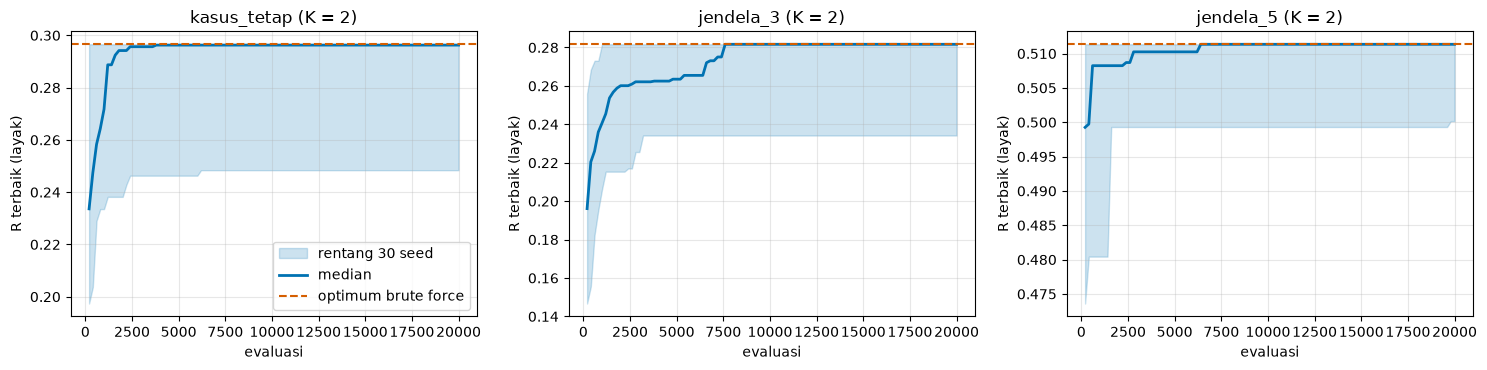

In [12]:
import warnings; warnings.simplefilter('ignore', RuntimeWarning)
# kurva konvergensi GA pada K = 2 (rata-rata dan rentang 30 seed) dibandingkan dengan optimum brute force
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=False)
for ax, nama in zip(axes, ["kasus_tetap", "jendela_3", "jendela_5"]):
    runs = hasil_k2[nama]
    H = np.array([[h[1] for h in r.history] for r in runs])
    ev_ax = [h[0] for h in runs[0].history]
    med = np.nanmedian(H, axis=0)
    ax.fill_between(ev_ax, np.nanmin(H, axis=0), np.nanmax(H, axis=0), color="#0072B2", alpha=0.2, label="rentang 30 seed")
    ax.plot(ev_ax, med, color="#0072B2", lw=2, label="median")
    ax.axhline(BF[nama]["kas bebas"][0], color="#D55E00", ls="--", label="optimum brute force")
    ax.set(title=f"{nama} (K = 2)", xlabel="evaluasi", ylabel="R terbaik (layak)")
    ax.grid(alpha=0.3)
axes[0].legend(loc="lower right")
plt.tight_layout(); plt.show()

## 9. Visualisasi proses GA

`ga_run(..., trace=True)` merekam seluruh populasi (100 individu) pada tiap generasi (200 generasi termasuk populasi
awal). Tiga gambar menunjukkan *bagaimana* GA mencapai hasilnya:

1. **Kurva proses:** R terbaik dan R rata-rata populasi layak (pita persentil 10–90), fraksi populasi yang layak,
   keragaman (jumlah himpunan saham berbeda), dan evolusi gen kas $g_0$ beserta sisa kas akhir portofolio terbaik.
2. **Peta risiko–return populasi** pada beberapa generasi: titik biru layak, oranye melanggar batas risiko
   (garis putus-putus = $\sigma_{\max}$), bintang = individu terbaik. Populasi awal tersebar luas, lalu GA mengerucutkannya ke tepi kanan area layak ($\sigma \approx \sigma_{\max}$), tempat return tertinggi berada.
3. **Komposisi portofolio terbaik** generasi demi generasi, termasuk porsi kas.

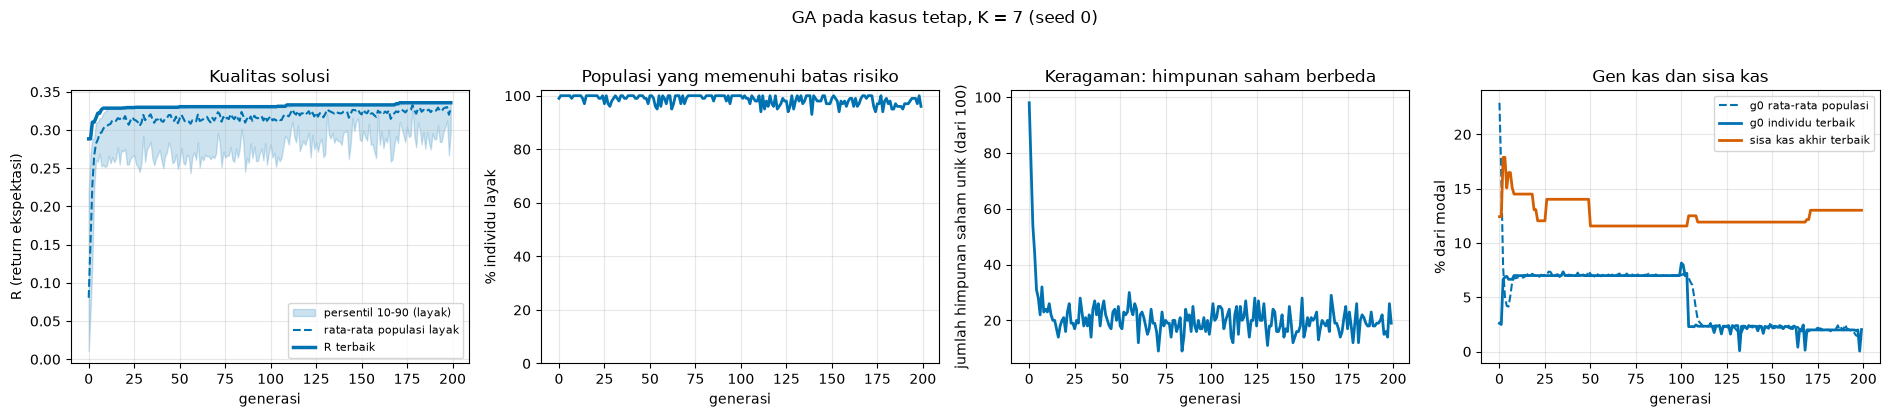

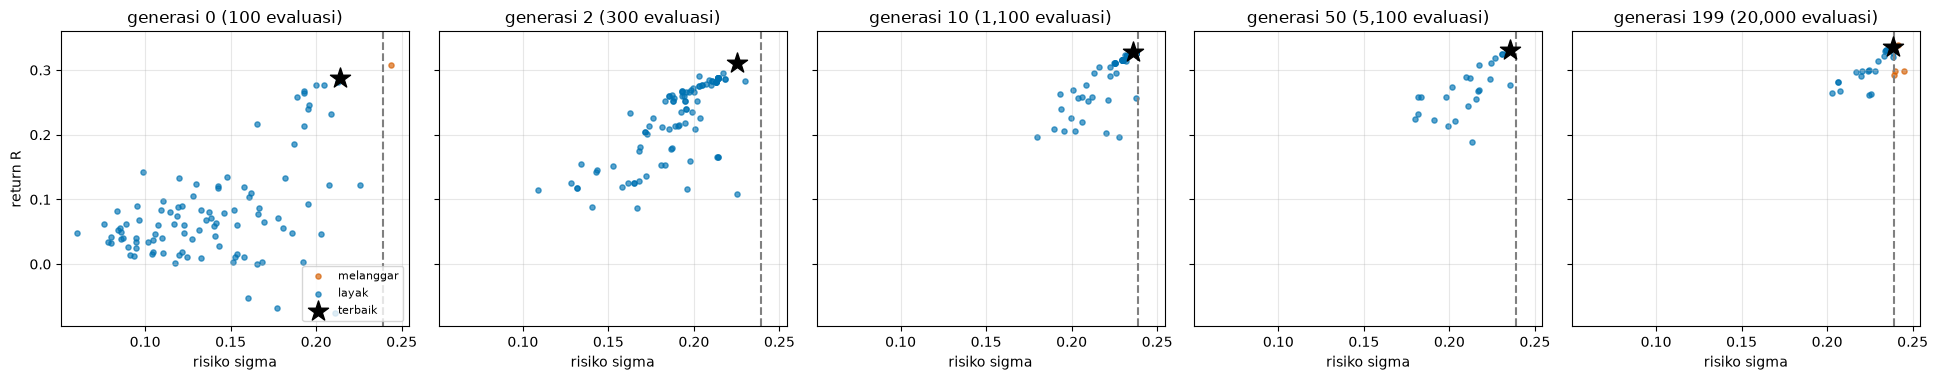

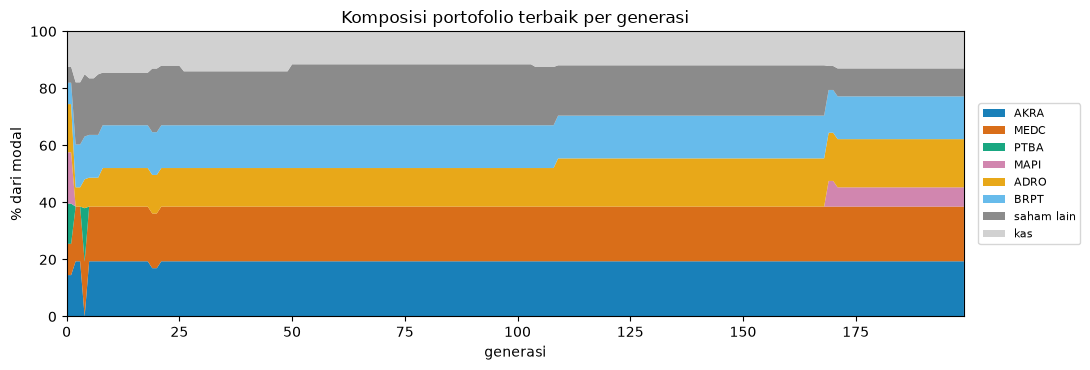

GA pada kasus tetap, K = 7 (seed 0)
  individu layak pertama pada generasi 0; R terbaik 0.2884 -> 0.3357 (generasi 199)
  populasi layak 99% (awal) -> 96% (akhir); himpunan saham unik 98 -> 19
  g0 rata-rata populasi 0.229 -> 0.011; sisa kas akhir terbaik Rp 650.500 (13.0%)

Portofolio hasil GA:
  Saham    Lot  Lembar  Harga/lembar    Nilai posisi   Bobot
  AKRA       8     800      Rp 1.210      Rp 968.000   19.4%
  MEDC       7     700      Rp 1.370      Rp 959.000   19.2%
  ADRO       5     500      Rp 1.690      Rp 845.000   16.9%
  BRPT       2     200      Rp 3.750      Rp 750.000   15.0%
  ESSA       7     700        Rp 700      Rp 490.000    9.8%
  MAPI       3     300      Rp 1.125      Rp 337.500    6.8%
  ----------------------------------------------------------
  Modal                           Rp 5.000.000
  Dana terpakai                   Rp 4.349.500   87.0%
  SISA KAS AKHIR                    Rp 650.500   13.0%
    - kas sengaja (g0 x D)               Rp 99.461
    - k

In [13]:
import warnings
warnings.simplefilter("ignore", RuntimeWarning)

WARNA_LAYAK, WARNA_LANGGAR = "#0072B2", "#D55E00"


def plot_proses_ga(res, P, judul, R_opt=None):
    tr = res.trace
    G = len(tr["R"]); ar = np.arange(G)
    layak = tr["viol"] <= 0
    j = np.array([deb_urut(tr["R"][g], tr["viol"][g])[0] for g in range(G)])     # individu terbaik per generasi
    R_best = np.where(layak[ar, j], tr["R"][ar, j], np.nan)
    Rf = np.where(layak, tr["R"], np.nan)
    R_mean, R_p10, R_p90 = np.nanmean(Rf, 1), np.nanpercentile(Rf, 10, 1), np.nanpercentile(Rf, 90, 1)
    g0_best, kas_best = tr["g0"][ar, j], tr["kas"][ar, j]

    # ---------- gambar 1: kurva proses ----------
    fig, ax = plt.subplots(1, 4, figsize=(19, 4))
    ax[0].fill_between(ar, R_p10, R_p90, color=WARNA_LAYAK, alpha=0.2, label="persentil 10-90 (layak)")
    ax[0].plot(ar, R_mean, color=WARNA_LAYAK, lw=1.5, ls="--", label="rata-rata populasi layak")
    ax[0].plot(ar, R_best, color=WARNA_LAYAK, lw=2.5, label="R terbaik")
    if R_opt is not None:
        ax[0].axhline(R_opt, color=WARNA_LANGGAR, ls=":", lw=2, label="optimum brute force")
    ax[0].set(title="Kualitas solusi", xlabel="generasi", ylabel="R (return ekspektasi)")
    ax[0].legend(fontsize=8, loc="lower right")
    ax[1].plot(ar, layak.mean(1) * 100, color=WARNA_LAYAK, lw=2)
    ax[1].set(title="Populasi yang memenuhi batas risiko", xlabel="generasi", ylabel="% individu layak", ylim=(0, 102))
    ax[2].plot(ar, tr["n_unik"], color=WARNA_LAYAK, lw=2)
    ax[2].set(title="Keragaman: himpunan saham berbeda", xlabel="generasi", ylabel="jumlah himpunan saham unik (dari 100)")
    ax[3].plot(ar, tr["g0"].mean(1) * 100, color=WARNA_LAYAK, lw=1.5, ls="--", label="g0 rata-rata populasi")
    ax[3].plot(ar, g0_best * 100, color=WARNA_LAYAK, lw=2, label="g0 individu terbaik")
    ax[3].plot(ar, kas_best * 100, color=WARNA_LANGGAR, lw=2, label="sisa kas akhir terbaik")
    ax[3].set(title="Gen kas dan sisa kas", xlabel="generasi", ylabel="% dari modal")
    ax[3].legend(fontsize=8)
    for a_ in ax:
        a_.grid(alpha=0.3)
    fig.suptitle(judul, y=1.03, fontsize=12)
    plt.tight_layout(); plt.show()

    # ---------- gambar 2: peta risiko-return populasi ----------
    snap = sorted({0, 2, 10, 50, G - 1})
    fig, ax = plt.subplots(1, len(snap), figsize=(3.9 * len(snap), 3.9), sharex=True, sharey=True)
    for a_, g in zip(ax, snap):
        l = layak[g]
        a_.scatter(tr["sigma"][g][~l], tr["R"][g][~l], s=14, color=WARNA_LANGGAR, alpha=0.65, label="melanggar")
        a_.scatter(tr["sigma"][g][l], tr["R"][g][l], s=14, color=WARNA_LAYAK, alpha=0.65, label="layak")
        a_.scatter(tr["sigma"][g][j[g]], tr["R"][g][j[g]], marker="*", s=230, color="black", zorder=5, label="terbaik")
        a_.axvline(P.sigma_max, color="gray", ls="--")
        a_.set(title=f"generasi {g} ({(g + 1) * GA_PARAM['pop']:,} evaluasi)", xlabel="risiko sigma")
        a_.grid(alpha=0.3)
    ax[0].set_ylabel("return R"); ax[0].legend(fontsize=8, loc="lower right")
    plt.tight_layout(); plt.show()

    # ---------- gambar 3: komposisi portofolio terbaik per generasi ----------
    Wb = tr["lots_terbaik"] * P.harga_lot / P.D                          # (G, N) bobot individu terbaik
    top = list(np.argsort(-Wb.max(0))[:6])
    lain = np.setdiff1d(np.arange(P.n), top)
    lapis = [Wb[:, i] * 100 for i in top] + [Wb[:, lain].sum(1) * 100, kas_best * 100]
    label = [P.tickers[i] for i in top] + ["saham lain", "kas"]
    warna = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#7f7f7f", "#cccccc"]
    fig, a_ = plt.subplots(figsize=(11, 3.8))
    a_.stackplot(ar, lapis, labels=label, colors=warna, alpha=0.9)
    a_.set(title="Komposisi portofolio terbaik per generasi", xlabel="generasi", ylabel="% dari modal", ylim=(0, 100), xlim=(0, G - 1))
    a_.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8)
    plt.tight_layout(); plt.show()

    g1 = int(np.argmax(layak.any(1))) if layak.any() else None
    print(f"{judul}")
    print(f"  individu layak pertama pada generasi {g1}; R terbaik {R_best[g1]:.4f} -> {R_best[-1]:.4f} (generasi {G - 1})")
    print(f"  populasi layak {layak[0].mean():.0%} (awal) -> {layak[-1].mean():.0%} (akhir); himpunan saham unik {tr['n_unik'][0]} -> {tr['n_unik'][-1]}")
    print(f"  g0 rata-rata populasi {tr['g0'][0].mean():.3f} -> {tr['g0'][-1].mean():.3f}; sisa kas akhir terbaik {rp(kas_best[-1] * P.D)} ({kas_best[-1]:.1%})")
    return res


# kasus 1: kasus tetap, K = 7 (cap 20% berlaku), seed 0
P = buat_problem(DATA["kasus_tetap"], 7)
res7 = ga_run(P, seed=0, trace=True)
plot_proses_ga(res7, P, "GA pada kasus tetap, K = 7 (seed 0)")
tabel_portofolio(P, res7.lots, res7.x, judul="\nPortofolio hasil GA:")

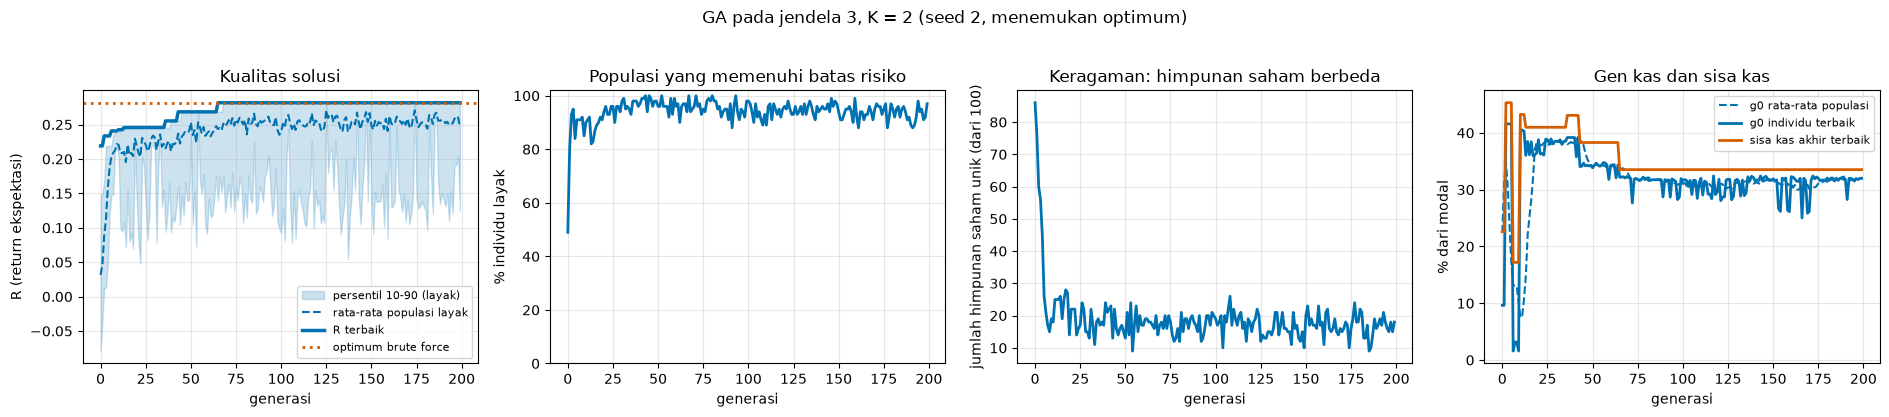

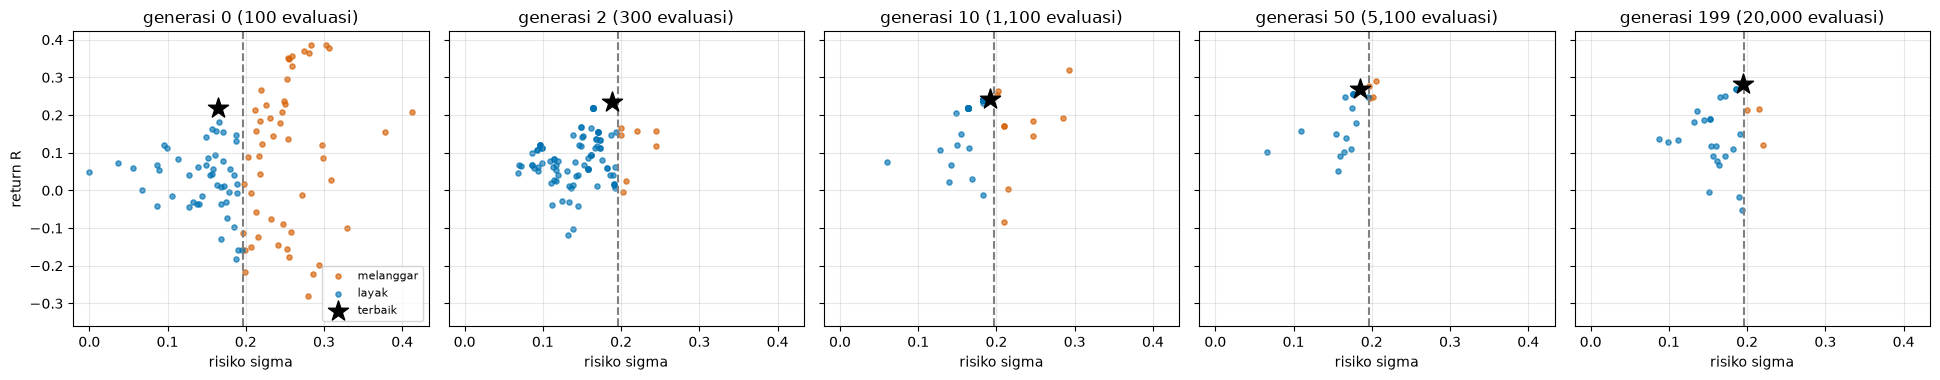

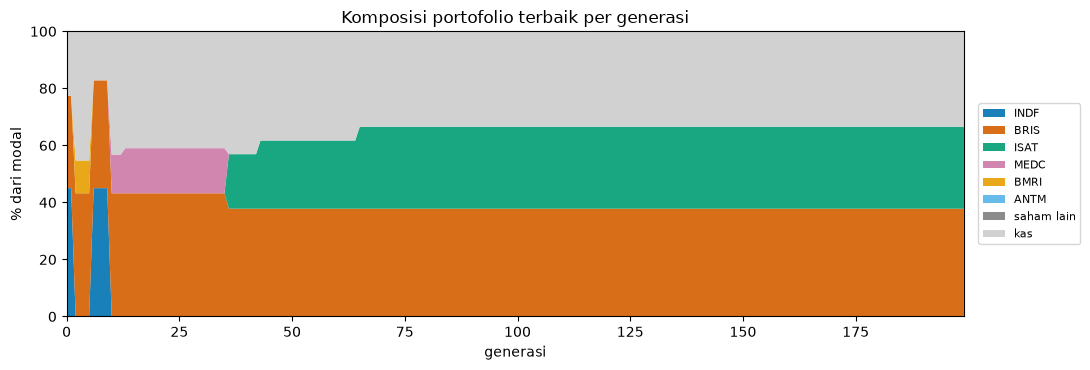

GA pada jendela 3, K = 2 (seed 2, menemukan optimum)
  individu layak pertama pada generasi 0; R terbaik 0.2190 -> 0.2817 (generasi 199)
  populasi layak 49% (awal) -> 97% (akhir); himpunan saham unik 86 -> 18
  g0 rata-rata populasi 0.224 -> 0.322; sisa kas akhir terbaik Rp 1.676.000 (33.5%)

Portofolio hasil GA:
  Saham    Lot  Lembar  Harga/lembar    Nilai posisi   Bobot
  BRIS       7     700      Rp 2.700    Rp 1.890.000   37.8%
  ISAT       6     600      Rp 2.390    Rp 1.434.000   28.7%
  ----------------------------------------------------------
  Modal                           Rp 5.000.000
  Dana terpakai                   Rp 3.324.000   66.5%
  SISA KAS AKHIR                  Rp 1.676.000   33.5%
    - kas sengaja (g0 x D)            Rp 1.609.835
    - kelebihan cap / tak teralokasi          Rp 0
    - sisa pembulatan lot                Rp 66.165


In [14]:
# kasus 2: jendela 3, K = 2, yang optimum sejatinya diketahui dari brute force (R* = 0,2817, kas 33,5%)
P = buat_problem(DATA["jendela_3"], 2)
R_star = BF["jendela_3"]["kas bebas"][0]
seed_ok = next(sd for sd in range(30) if (lambda r: r.feasible and r.R >= R_star - 1e-9)(ga_run(P, seed=sd)))
run_cat = ga_run(P, seed=seed_ok, trace=True)
plot_proses_ga(run_cat, P, f"GA pada jendela 3, K = 2 (seed {run_cat.seed}, menemukan optimum)", R_opt=R_star)
tabel_portofolio(P, run_cat.lots, run_cat.x, judul="\nPortofolio hasil GA:")

## 10. Perbandingan setiap K

GA dijalankan untuk **semua** $K \in \{2, 3, 5, 7, 10\}$ pada data yang sama dengan 30 seed per K (anggaran 20.000
evaluasi per run). Hanya ada dua aturan yang berubah antar K: batas jumlah saham, dan batas 20% per saham yang
baru berlaku mulai $K = 7$. Ganti `DATA_K` untuk membandingkan pada jendela lain.

In [15]:
import pandas as pd

DATA_K = "kasus_tetap"        # pilihan: kasus_tetap, jendela_1 ... jendela_5
N_SEED_K = 30

hasil_K = {}
for K in K_LIST:
    P = buat_problem(DATA[DATA_K], K, label=DATA_K)
    hasil_K[K] = (P, [ga_run(P, seed=s) for s in range(N_SEED_K)])

# pemeriksaan kendala pada SEMUA run semua K
for K, (P, runs) in hasil_K.items():
    for r in runs:
        assert (r.lots > 0).sum() <= K and r.n_eval == BUDGET
        assert (r.lots * P.harga_lot).sum() <= P.D + 1e-6
        assert (r.lots * P.harga_lot / P.D).max() <= P.cap + 1e-9
print(f"kendala (kardinalitas, cap, dana <= D, anggaran 20.000) terpenuhi pada {N_SEED_K * len(K_LIST)} run")

terbaik_K = {K: max((r for r in runs if r.feasible), key=lambda r: r.R, default=runs[0]) for K, (P, runs) in hasil_K.items()}
kas_rp = {K: np.array([P.D - (r.lots * P.harga_lot).sum() for r in runs]) for K, (P, runs) in hasil_K.items()}
Rlayak = {K: np.array([r.R for r in runs if r.feasible] or [np.nan]) for K, (P, runs) in hasil_K.items()}

baris = []
for K, (P, runs) in hasil_K.items():
    b = terbaik_K[K]
    baris.append({
        "K": K, "cap": f"{P.cap:.0%}" if P.cap < 1 else "-",
        "layak": f"{np.mean([r.feasible for r in runs]):.0%}",
        "R median": f"{np.median(Rlayak[K]):.4f}", "R maks": f"{Rlayak[K].max():.4f}",
        "R min": f"{Rlayak[K].min():.4f}", "std R": f"{Rlayak[K].std():.4f}",
        "saham (median)": f"{np.median([(r.lots > 0).sum() for r in runs]):.0f}",
        "bobot maks": f"{np.median([(r.lots * P.harga_lot / P.D).max() for r in runs]):.1%}",
        "sigma terbaik / batas": f"{b.sigma:.3f} / {P.sigma_max:.3f}",
        "sisa kas median": rp(np.median(kas_rp[K])), "(%)": f"{np.median(kas_rp[K]) / P.D:.1%}",
        "eval s.d. terbaik": f"{np.median([r.n_eval_best for r in runs]):,.0f}",
        "detik/run": f"{np.mean([r.seconds for r in runs]):.2f}"})
tabel_K = pd.DataFrame(baris)
print(f"Perbandingan K pada {DATA_K} (D = {rp(D)}, sigma_max = 1,5x vol 1/N, {N_SEED_K} seed per K)\n")
print(tabel_K.to_string(index=False))

kendala (kardinalitas, cap, dana <= D, anggaran 20.000) terpenuhi pada 150 run
Perbandingan K pada kasus_tetap (D = Rp 5.000.000, sigma_max = 1,5x vol 1/N, 30 seed per K)

 K cap layak R median R maks  R min  std R saham (median) bobot maks sigma terbaik / batas sisa kas median   (%) eval s.d. terbaik detik/run
 2   -  100%   0.2963 0.2966 0.2484 0.0106              2      37.5%         0.238 / 0.239    Rp 1.913.000 38.3%             1,158      0.21
 3   -  100%   0.3010 0.3223 0.2950 0.0078              3      30.4%         0.238 / 0.239    Rp 1.422.000 28.4%             6,267      0.21
 5   -  100%   0.3333 0.3395 0.3221 0.0040              4      23.7%         0.238 / 0.239    Rp 1.129.000 22.6%            12,440      0.21
 7 20%  100%   0.3372 0.3413 0.3206 0.0035              7      19.2%         0.239 / 0.239      Rp 445.000  8.9%            15,418      0.23
10 20%  100%   0.3162 0.3400 0.2967 0.0116              9      16.4%         0.237 / 0.239      Rp 224.750  4.5%           

In [16]:
# portofolio terbaik (R tertinggi yang layak) untuk setiap K, lengkap dengan sisa kas dalam Rupiah
for K in K_LIST:
    P, runs = hasil_K[K]
    r = terbaik_K[K]
    tabel_portofolio(P, r.lots, r.x, judul=f"K = {K}: R = {r.R:.4f}, sigma = {r.sigma:.4f} (batas {P.sigma_max:.4f}), seed {r.seed}")
    print()

K = 2: R = 0.2966, sigma = 0.2377 (batas 0.2390), seed 1
  Saham    Lot  Lembar  Harga/lembar    Nilai posisi   Bobot
  ITMG       1     100     Rp 22.875    Rp 2.287.500   45.8%
  BRPT       4     400      Rp 3.750    Rp 1.500.000   30.0%
  ----------------------------------------------------------
  Modal                           Rp 5.000.000
  Dana terpakai                   Rp 3.787.500   75.8%
  SISA KAS AKHIR                  Rp 1.212.500   24.2%
    - kas sengaja (g0 x D)              Rp 449.183
    - kelebihan cap / tak teralokasi          Rp 0
    - sisa pembulatan lot               Rp 763.317

K = 3: R = 0.3223, sigma = 0.2385 (batas 0.2390), seed 15
  Saham    Lot  Lembar  Harga/lembar    Nilai posisi   Bobot
  ADRO      10    1000      Rp 1.690    Rp 1.690.000   33.8%
  BRPT       3     300      Rp 3.750    Rp 1.125.000   22.5%
  MEDC       5     500      Rp 1.370      Rp 685.000   13.7%
  ----------------------------------------------------------
  Modal                  

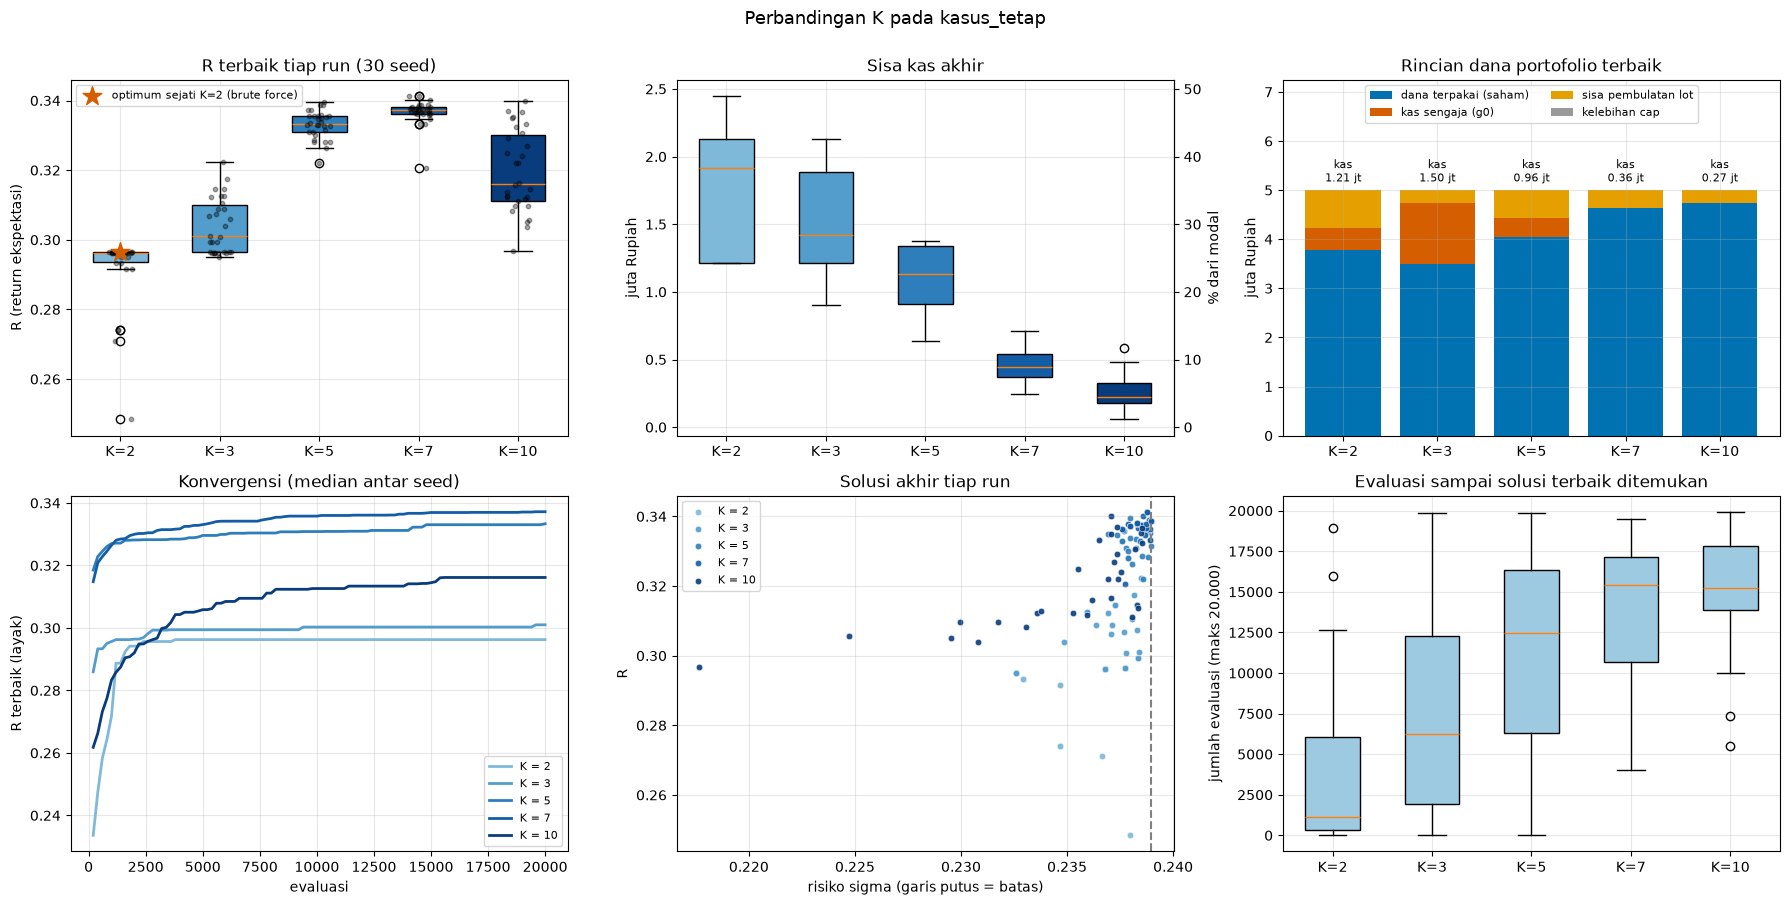

In [17]:
warnaK = {K: plt.cm.Blues(0.45 + 0.5 * i / (len(K_LIST) - 1)) for i, K in enumerate(K_LIST)}   # K berurutan -> satu warna
R_opt_K2 = BF.get(DATA_K, {}).get("kas bebas", (None,))[0]                                    # optimum sejati K = 2 bila ada

fig, ax = plt.subplots(2, 3, figsize=(18, 9))

# (1) sebaran R terbaik antar seed
bp = ax[0, 0].boxplot([Rlayak[K] for K in K_LIST], tick_labels=[f"K={K}" for K in K_LIST], patch_artist=True, widths=0.55)
for patch, K in zip(bp["boxes"], K_LIST):
    patch.set_facecolor(warnaK[K])
for i, K in enumerate(K_LIST, 1):
    ax[0, 0].scatter(np.full(len(Rlayak[K]), i) + np.random.default_rng(i).uniform(-0.12, 0.12, len(Rlayak[K])),
                     Rlayak[K], s=10, color="black", alpha=0.35, zorder=3)
if R_opt_K2 is not None:
    ax[0, 0].scatter([1], [R_opt_K2], marker="*", s=200, color=WARNA_LANGGAR, zorder=5, label="optimum sejati K=2 (brute force)")
    ax[0, 0].legend(fontsize=8)
ax[0, 0].set(title="R terbaik tiap run (30 seed)", ylabel="R (return ekspektasi)")

# (2) sisa kas akhir dalam Rupiah
bp = ax[0, 1].boxplot([kas_rp[K] / 1e6 for K in K_LIST], tick_labels=[f"K={K}" for K in K_LIST], patch_artist=True, widths=0.55)
for patch, K in zip(bp["boxes"], K_LIST):
    patch.set_facecolor(warnaK[K])
ax[0, 1].set(title="Sisa kas akhir", ylabel="juta Rupiah")
sec = ax[0, 1].secondary_yaxis("right", functions=(lambda y: y * 1e6 / D * 100, lambda y: y * D / 1e6 / 100))
sec.set_ylabel("% dari modal")

# (3) rincian dana portofolio terbaik tiap K (juta Rp): saham vs tiga komponen sisa kas
rin = {K: rincian_kas(terbaik_K[K].x, hasil_K[K][0]) for K in K_LIST}
komponen = [("terpakai", "dana terpakai (saham)", "#0072B2"), ("kas_sengaja", "kas sengaja (g0)", "#D55E00"),
            ("kas_pembulatan", "sisa pembulatan lot", "#E69F00"), ("kas_cap", "kelebihan cap", "#999999")]
bawah = np.zeros(len(K_LIST))
for kunci, nama_k, warna_k in komponen:
    nilai = np.array([rin[K][kunci] for K in K_LIST]) / 1e6
    ax[0, 2].bar([f"K={K}" for K in K_LIST], nilai, bottom=bawah, color=warna_k, label=nama_k)
    bawah += nilai
for i, K in enumerate(K_LIST):
    ax[0, 2].text(i, D / 1e6 * 1.02, f"kas\n{rin[K]['kas_akhir'] / 1e6:.2f} jt", ha="center", va="bottom", fontsize=8)
ax[0, 2].set(title="Rincian dana portofolio terbaik", ylabel="juta Rupiah", ylim=(0, D / 1e6 * 1.45))
ax[0, 2].legend(fontsize=8, loc="upper center", ncol=2)

# (4) konvergensi (median antar seed)
for K in K_LIST:
    H = np.array([[h[1] for h in r.history] for r in hasil_K[K][1]])
    x_ = [h[0] for h in hasil_K[K][1][0].history]
    ax[1, 0].plot(x_, np.nanmedian(H, 0), color=warnaK[K], lw=2, label=f"K = {K}")
ax[1, 0].set(title="Konvergensi (median antar seed)", xlabel="evaluasi", ylabel="R terbaik (layak)")
ax[1, 0].legend(fontsize=8, loc="lower right")

# (5) peta risiko-return solusi akhir tiap run
for K in K_LIST:
    P, runs = hasil_K[K]
    ax[1, 1].scatter([r.sigma for r in runs], [r.R for r in runs], s=22, color=warnaK[K], edgecolor="white", linewidth=0.4,
                     alpha=0.9, label=f"K = {K}")
ax[1, 1].axvline(hasil_K[K_LIST[0]][0].sigma_max, color="gray", ls="--")
ax[1, 1].set(title="Solusi akhir tiap run", xlabel="risiko sigma (garis putus = batas)", ylabel="R")
ax[1, 1].legend(fontsize=8)

# (6) usaha pencarian: evaluasi sampai solusi terbaik ditemukan
ax[1, 2].boxplot([[r.n_eval_best for r in hasil_K[K][1]] for K in K_LIST], tick_labels=[f"K={K}" for K in K_LIST], patch_artist=True,
                 widths=0.55, boxprops=dict(facecolor="#9ecae1"))
ax[1, 2].set(title="Evaluasi sampai solusi terbaik ditemukan", ylabel="jumlah evaluasi (maks 20.000)")

for a_ in ax.ravel():
    a_.grid(alpha=0.3)
fig.suptitle(f"Perbandingan K pada {DATA_K}", y=1.0, fontsize=13)
plt.tight_layout(); plt.show()

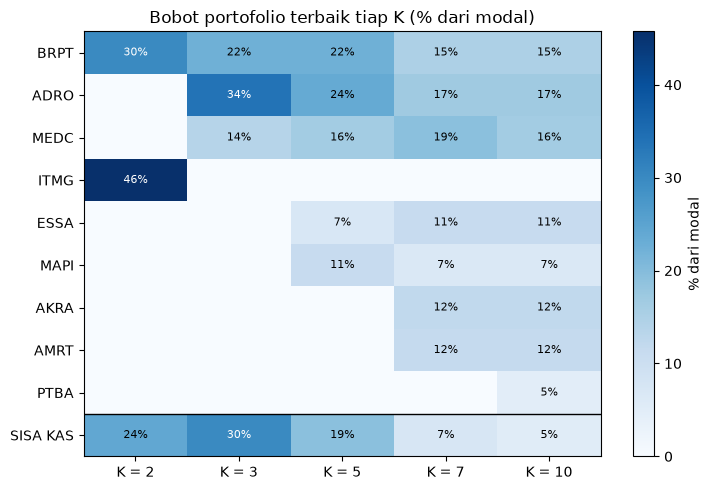

In [18]:
# peta panas: bobot portofolio terbaik tiap K (baris = saham, kolom = K), baris terakhir = sisa kas
saham = sorted({hasil_K[K][0].tickers[i] for K in K_LIST for i in np.where(terbaik_K[K].lots > 0)[0]})
W = np.zeros((len(saham) + 1, len(K_LIST)))
for c, K in enumerate(K_LIST):
    P = hasil_K[K][0]; r = terbaik_K[K]
    w_ = r.lots * P.harga_lot / P.D
    for i in np.where(r.lots > 0)[0]:
        W[saham.index(P.tickers[i]), c] = w_[i]
    W[-1, c] = 1 - w_.sum()
urut = np.argsort(-W[:-1].sum(1))                                  # saham yang paling sering/besar di atas
W = np.vstack([W[:-1][urut], W[-1:]])
nama_baris = [saham[i] for i in urut] + ["SISA KAS"]

fig, a_ = plt.subplots(figsize=(7.5, 0.34 * len(nama_baris) + 1.6))
im = a_.imshow(W * 100, cmap="Blues", aspect="auto", vmin=0, vmax=max(W.max() * 100, 1))
a_.set_xticks(range(len(K_LIST)), [f"K = {K}" for K in K_LIST]); a_.set_yticks(range(len(nama_baris)), nama_baris)
for i in range(W.shape[0]):
    for c in range(W.shape[1]):
        if W[i, c] > 0:
            a_.text(c, i, f"{W[i, c] * 100:.0f}%", ha="center", va="center", fontsize=8,
                    color="white" if W[i, c] * 100 > 0.6 * W.max() * 100 else "black")
a_.axhline(len(nama_baris) - 1.5, color="black", lw=1)
a_.set_title("Bobot portofolio terbaik tiap K (% dari modal)")
plt.colorbar(im, ax=a_, label="% dari modal")
plt.tight_layout(); plt.show()

In [19]:
m = {K: np.median(Rlayak[K]) for K in K_LIST}
print("R median GA per K :", {K: round(float(v), 4) for K, v in m.items()})
print("sisa kas median   :", {K: rp(np.median(kas_rp[K])) for K in K_LIST})
print()
print("Cara membaca: K = 2, 3, 5 tanpa batas per saham; K = 7 dan 10 memakai cap 20%, sehingga hasil kedua kelompok")
print("tidak sepenuhnya sebanding. Dalam satu kelompok, K lebih besar memuat semua solusi K lebih kecil, jadi optimum")
print("sejati tidak pernah turun saat K naik.")
for a, b in [(2, 3), (3, 5), (7, 10)]:
    if m[b] < m[a] - 1e-4:
        print(f"  K = {b} (R median {m[b]:.4f}) lebih rendah dari K = {a} ({m[a]:.4f}) padahal ruang solusinya memuat K = {a}: "
              f"GA belum menemukan optimum pada K = {b}.")

R median GA per K : {2: 0.2963, 3: 0.301, 5: 0.3333, 7: 0.3372, 10: 0.3162}
sisa kas median   : {2: 'Rp 1.913.000', 3: 'Rp 1.422.000', 5: 'Rp 1.129.000', 7: 'Rp 445.000', 10: 'Rp 224.750'}

Cara membaca: K = 2, 3, 5 tanpa batas per saham; K = 7 dan 10 memakai cap 20%, sehingga hasil kedua kelompok
tidak sepenuhnya sebanding. Dalam satu kelompok, K lebih besar memuat semua solusi K lebih kecil, jadi optimum
sejati tidak pernah turun saat K naik.
  K = 10 (R median 0.3162) lebih rendah dari K = 7 (0.3372) padahal ruang solusinya memuat K = 7: GA belum menemukan optimum pada K = 10.


## 11. Penjelasan pemilihan saham dan return yang diharapkan

Bagian ini menjawab: *dengan modal $D$, berapa persen return maksimum yang dapat diharapkan, dari saham mana return itu
berasal, dan mengapa saham itu yang dipilih?*

**Cara membaca "return":** $R = \sum_i w_i \mu_i + w_0 r_f$ adalah **return ekspektasi per tahun sebagai persen dari modal**.
$\mu_i$ adalah rata-rata return harian saham $i$ pada data latih dikali 252. Bagian 11.1–11.6 adalah ekspektasi *dalam
sampel* (termasuk total nilai dan hasil akhir); bagian 11.7 menguji portofolio yang sama pada **data uji** yang tidak dipakai optimasi.

In [20]:
def analisis(P, lots):
    # Penguraian return dan risiko satu portofolio (semua dalam pecahan dari modal).
    nilai = lots * P.harga_lot
    w = nilai / P.D
    kas = 1.0 - w.sum()
    sigma = float(np.sqrt(w @ P.cov @ w))
    return dict(w=w, kas=kas, sigma=sigma,
                R_saham=w * P.mu,                              # kontribusi return tiap saham
                R_kas=kas * P.rf,                              # kontribusi kas (bernilai r_f)
                R=float((w * P.mu).sum() + kas * P.rf),
                kontr_risiko=w * (P.cov @ w) / sigma ** 2)     # kontribusi tiap saham terhadap varians portofolio


AN = {K: analisis(hasil_K[K][0], terbaik_K[K].lots) for K in K_LIST}
for K in K_LIST:                                               # konsistensi dengan hasil GA
    assert abs(AN[K]["R"] - terbaik_K[K].R) < 1e-9 and abs(AN[K]["sigma"] - terbaik_K[K].sigma) < 1e-9

# pembanding: 1/N pada 42 saham (bobot sama rata, tanpa lot dan tanpa kas)
P0 = hasil_K[K_LIST[0]][0]
R_eq, sigma_eq = float(P0.mu.mean()), float(np.sqrt(np.full(P0.n, 1 / P0.n) @ P0.cov @ np.full(P0.n, 1 / P0.n)))

baris = []
for K in K_LIST:
    P, A = hasil_K[K][0], AN[K]
    baris.append({"K": K, "return ekspektasi (% modal / tahun)": f"{A['R']:.1%}", "setara Rp / tahun": rp(A["R"] * D),
                  "di atas kas murni (poin %)": f"{(A['R'] - RF) * 100:+.1f}", "risiko sigma": f"{A['sigma']:.1%}",
                  "sigma / batas": f"{A['sigma'] / P.sigma_max:.0%}", "(R - rf) / sigma": f"{(A['R'] - RF) / A['sigma']:.2f}",
                  "saham": int((terbaik_K[K].lots > 0).sum()), "sisa kas": f"{rp(A['kas'] * D)} ({A['kas']:.1%})"})
baris.append({"K": "1/N", "return ekspektasi (% modal / tahun)": f"{R_eq:.1%}", "setara Rp / tahun": rp(R_eq * D),
              "di atas kas murni (poin %)": f"{(R_eq - RF) * 100:+.1f}", "risiko sigma": f"{sigma_eq:.1%}", "sigma / batas": "-",
              "(R - rf) / sigma": f"{(R_eq - RF) / sigma_eq:.2f}", "saham": P0.n, "sisa kas": "- (tanpa lot)"})
print(f"Return ekspektasi tertinggi yang ditemukan GA per K ({DATA_K}, modal {rp(D)}, batas risiko {P0.sigma_max:.1%})")
print(f"Menyimpan seluruh dana sebagai kas saja: {RF:.1%} per tahun = {rp(RF * D)}\n")
print(pd.DataFrame(baris).to_string(index=False))

Return ekspektasi tertinggi yang ditemukan GA per K (kasus_tetap, modal Rp 5.000.000, batas risiko 23.9%)
Menyimpan seluruh dana sebagai kas saja: 5.0% per tahun = Rp 250.000

  K return ekspektasi (% modal / tahun) setara Rp / tahun di atas kas murni (poin %) risiko sigma sigma / batas (R - rf) / sigma  saham             sisa kas
  2                               29.7%      Rp 1.482.881                      +24.7        23.8%           99%             1.04      2 Rp 1.212.500 (24.2%)
  3                               32.2%      Rp 1.611.460                      +27.2        23.8%          100%             1.14      3 Rp 1.500.000 (30.0%)
  5                               34.0%      Rp 1.697.722                      +29.0        23.8%          100%             1.22      5   Rp 957.500 (19.1%)
  7                               34.1%      Rp 1.706.720                      +29.1        23.9%          100%             1.22      7    Rp 364.500 (7.3%)
 10                               34.0%

In [21]:
# ---- penguraian portofolio dengan return tertinggi ----
K_best = max(K_LIST, key=lambda K: AN[K]["R"])
P, rb, A = hasil_K[K_best][0], terbaik_K[K_best], AN[K_best]
rank_mu = (-P.mu).argsort().argsort() + 1                     # peringkat mu dari 42 saham (1 = tertinggi)
idx = np.where(rb.lots > 0)[0]
idx = idx[np.argsort(-A["R_saham"][idx])]

print(f"Portofolio dengan return tertinggi: K = {K_best} (seed {rb.seed}, {DATA_K}, tanggal beli {DATA[DATA_K]['tanggal_latih_akhir']})\n")
print(f"{'Saham':<7}{'Lot':>4}{'Nilai posisi':>14}{'Bobot':>7}{'mu saham':>10}{'peringkat mu':>13}{'vol saham':>10}"
      f"{'Return (% modal)':>18}{'Return (Rp/th)':>16}{'Porsi risiko':>13}")
for i in idx:
    print(f"{P.tickers[i]:<7}{rb.lots[i]:>4}{rp(rb.lots[i] * P.harga_lot[i]):>14}{A['w'][i]:>7.1%}{P.mu[i]:>10.1%}{rank_mu[i]:>10}/{P.n:<3}"
          f"{P.vol[i]:>10.1%}{A['R_saham'][i]:>18.2%}{rp(A['R_saham'][i] * D):>16}{A['kontr_risiko'][i]:>13.1%}")
print(f"{'KAS':<7}{'':>4}{rp(A['kas'] * D):>14}{A['kas']:>7.1%}{P.rf:>10.1%}{'(r_f)':>13}{'-':>10}{A['R_kas']:>18.2%}{rp(A['R_kas'] * D):>16}{'-':>13}")
print("-" * 118)
print(f"{'TOTAL':<7}{'':>4}{rp(D):>14}{1:>7.0%}{'':>10}{'':>13}{'':>10}{A['R']:>18.2%}{rp(A['R'] * D):>16}{sum(A['kontr_risiko'][idx]):>13.0%}")
rumus = " + ".join(f"{A['w'][i]:.1%} x {P.mu[i]:.1%}" for i in idx)
print(f"\nR = {rumus} + {A['kas']:.1%} x {P.rf:.0%} (kas)\n  = {A['R']:.2%} per tahun dari modal = {rp(A['R'] * D)} per tahun")
print(f"risiko sigma = {A['sigma']:.2%} per tahun (batas {P.sigma_max:.2%}); dalam 6 bulan (126 hari bursa) kira-kira {rp(A['R'] * D * 126 / 252)} bila ekspektasi terpenuhi")

Portofolio dengan return tertinggi: K = 7 (seed 3, kasus_tetap, tanggal beli 2025-09-30)

Saham   Lot  Nilai posisi  Bobot  mu saham peringkat mu vol saham  Return (% modal)  Return (Rp/th) Porsi risiko
MEDC      7    Rp 959.000  19.2%     42.7%         2/42      49.7%             8.19%      Rp 409.523        27.1%
BRPT      2    Rp 750.000  15.0%     52.7%         1/42      58.8%             7.90%      Rp 394.905        19.4%
ADRO      5    Rp 845.000  16.9%     38.6%         4/42      43.8%             6.52%      Rp 325.793        18.4%
ESSA      8    Rp 560.000  11.2%     38.9%         3/42      60.7%             4.35%      Rp 217.714        15.2%
AKRA      5    Rp 605.000  12.1%     26.5%         6/42      40.4%             3.21%      Rp 160.439        10.1%
AMRT      3    Rp 579.000  11.6%     19.3%        11/42      38.7%             2.23%      Rp 111.548         6.5%
MAPI      3    Rp 337.500   6.8%     20.3%        10/42      46.0%             1.37%       Rp 68.573         3.3%

Rata-rata (mu - r_f) / vol:   saham terpilih (terbobot) 0.64   |   seluruh 42 saham 0.07
Rata-rata korelasi pasangan:  antar saham terpilih 0.13   |   antar seluruh 42 saham 0.16


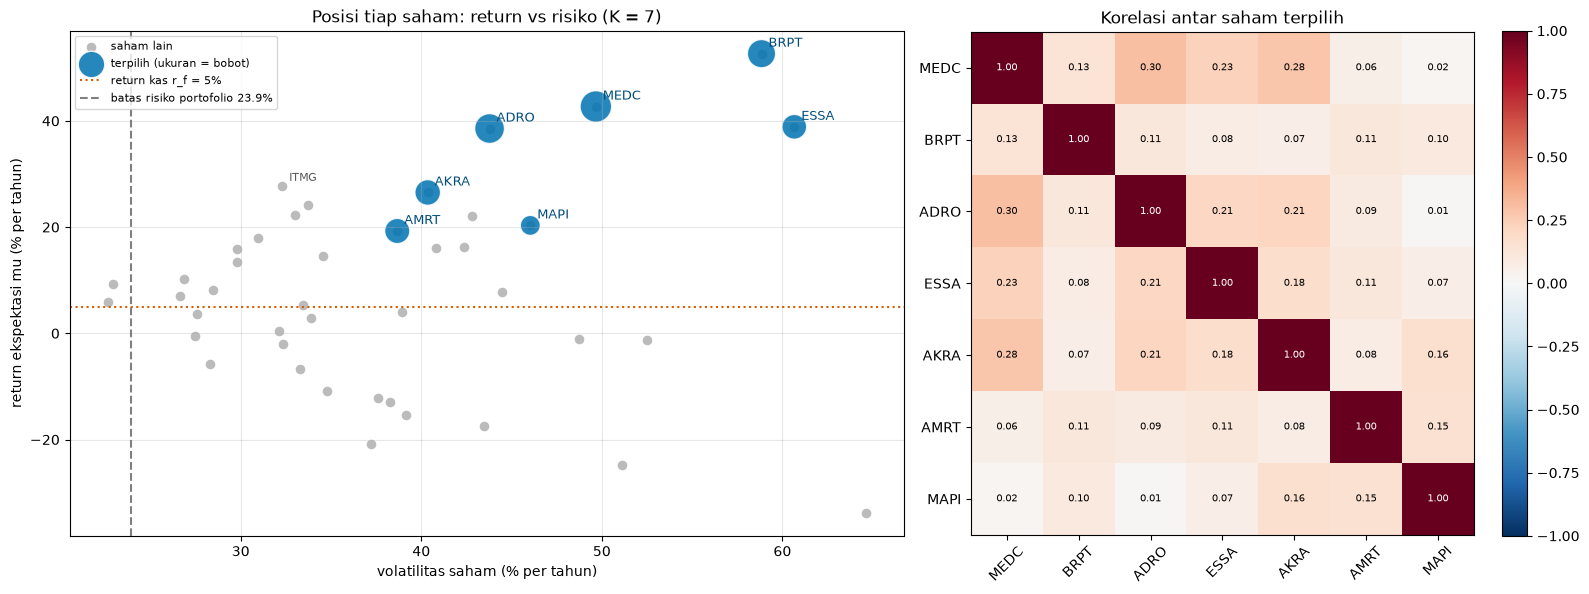

In [22]:
# ---- mengapa saham-saham ini? return per unit risiko dan diversifikasi ----
corr = P.cov / np.outer(P.vol, P.vol)
rasio = (P.mu - P.rf) / P.vol
sel = list(idx)
korel_pair = corr[np.ix_(sel, sel)][np.triu_indices(len(sel), 1)].mean()
korel_semua = corr[np.triu_indices(P.n, 1)].mean()
rasio_pf = float(((A["w"][sel] * rasio[sel]).sum() / A["w"][sel].sum()))
print(f"Rata-rata (mu - r_f) / vol:   saham terpilih (terbobot) {rasio_pf:.2f}   |   seluruh 42 saham {rasio.mean():.2f}")
print(f"Rata-rata korelasi pasangan:  antar saham terpilih {korel_pair:.2f}   |   antar seluruh 42 saham {korel_semua:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.5, 1]})
a0 = ax[0]
a0.scatter(P.vol * 100, P.mu * 100, s=35, color="#bbbbbb", label="saham lain")
a0.scatter(P.vol[sel] * 100, P.mu[sel] * 100, s=A["w"][sel] * 2500 + 40, color=WARNA_LAYAK, alpha=0.85, edgecolor="white", label="terpilih (ukuran = bobot)")
for i in sel:
    a0.annotate(P.tickers[i], (P.vol[i] * 100, P.mu[i] * 100), xytext=(5, 5), textcoords="offset points", fontsize=9, color="#004c7a")
for i in np.argsort(-P.mu)[:6]:
    if i not in sel:
        a0.annotate(P.tickers[i], (P.vol[i] * 100, P.mu[i] * 100), xytext=(5, 4), textcoords="offset points", fontsize=8, color="#555555")
a0.axhline(RF * 100, color=WARNA_LANGGAR, ls=":", label=f"return kas r_f = {RF:.0%}")
a0.axvline(P.sigma_max * 100, color="gray", ls="--", label=f"batas risiko portofolio {P.sigma_max:.1%}")
a0.set(title=f"Posisi tiap saham: return vs risiko (K = {K_best})", xlabel="volatilitas saham (% per tahun)", ylabel="return ekspektasi mu (% per tahun)")
a0.legend(fontsize=8, loc="upper left"); a0.grid(alpha=0.3)

a1 = ax[1]
cs = corr[np.ix_(sel, sel)]
im = a1.imshow(cs, cmap="RdBu_r", vmin=-1, vmax=1)
a1.set_xticks(range(len(sel)), [P.tickers[i] for i in sel], rotation=45); a1.set_yticks(range(len(sel)), [P.tickers[i] for i in sel])
for r_ in range(len(sel)):
    for c_ in range(len(sel)):
        a1.text(c_, r_, f"{cs[r_, c_]:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(cs[r_, c_]) > 0.6 else "black")
a1.set_title("Korelasi antar saham terpilih"); plt.colorbar(im, ax=a1, fraction=0.046)
plt.tight_layout(); plt.show()

In [23]:
# ---- mengapa saham dengan mu tertinggi tidak otomatis dipilih ----
wsel = A["w"]
baris = []
for j in np.argsort(-P.mu)[:8]:
    terpilih = j in sel
    msk = np.ones(P.n, bool); msk[j] = False
    kor = float((corr[j][msk] @ wsel[msk]) / wsel[msk].sum())      # korelasi rata-rata terbobot dengan portofolio (tanpa dirinya)
    if terpilih:
        alasan = "DIPILIH"
    elif P.harga_lot[j] > P.D * P.cap:
        alasan = "1 lot melebihi batas dana per saham"
    elif rasio[j] < min(rasio[sel]):
        alasan = "return per unit risiko lebih rendah dari semua saham terpilih"
    elif kor > 0.5:
        alasan = f"berkorelasi tinggi dengan portofolio ({kor:.2f}): kurang menambah diversifikasi"
    else:
        alasan = "tergeser kombinasi lain (batas K dan batas risiko)"
    baris.append({"saham": P.tickers[j], "peringkat mu": rank_mu[j], "mu": f"{P.mu[j]:.1%}", "vol": f"{P.vol[j]:.1%}",
                  "(mu - rf)/vol": f"{rasio[j]:.2f}", "harga 1 lot": rp(P.harga_lot[j]), "korelasi dg portofolio": f"{kor:.2f}", "keterangan": alasan})
print("Delapan saham dengan return ekspektasi (mu) tertinggi dan statusnya:\n")
print(pd.DataFrame(baris).to_string(index=False))

Delapan saham dengan return ekspektasi (mu) tertinggi dan statusnya:

saham  peringkat mu    mu   vol (mu - rf)/vol  harga 1 lot korelasi dg portofolio                                         keterangan
 BRPT             1 52.7% 58.8%          0.81   Rp 375.000                   0.10                                            DIPILIH
 MEDC             2 42.7% 49.7%          0.76   Rp 137.000                   0.19                                            DIPILIH
 ESSA             3 38.9% 60.7%          0.56    Rp 70.000                   0.16                                            DIPILIH
 ADRO             4 38.6% 43.8%          0.77   Rp 169.000                   0.18                                            DIPILIH
 ITMG             5 27.6% 32.3%          0.70 Rp 2.287.500                   0.24                1 lot melebihi batas dana per saham
 AKRA             6 26.5% 40.4%          0.53   Rp 121.000                   0.17                                            DIPILIH

### 11.5 Total return ekspektasi (modal + return) per K

**Total nilai** = modal + return ekspektasi. Return dipecah menjadi return dari **saham** ($\sum_i w_i \mu_i \cdot D$) dan dari
**kas** ($w_0 r_f D$). Horizon 1 tahun mengikuti definisi $R$ (per tahun); horizon 6 bulan memakai skala linear
$126/252$. Ini ekspektasi dalam sampel, bukan hasil nyata (hasil nyata ada di 11.7).

Total nilai ekspektasi (modal + return), modal Rp 5.000.000, kasus_tetap

             K        modal return dari saham return dari kas total return / tahun TOTAL 1 tahun (modal + return) % dari modal TOTAL 6 bulan
             2 Rp 5.000.000      Rp 1.422.256       Rp 60.625         Rp 1.482.881                   Rp 6.482.881       129.7%  Rp 5.741.441
             3 Rp 5.000.000      Rp 1.536.460       Rp 75.000         Rp 1.611.460                   Rp 6.611.460       132.2%  Rp 5.805.730
             5 Rp 5.000.000      Rp 1.649.847       Rp 47.875         Rp 1.697.722                   Rp 6.697.722       134.0%  Rp 5.848.861
             7 Rp 5.000.000      Rp 1.688.495       Rp 18.225         Rp 1.706.720                   Rp 6.706.720       134.1%  Rp 5.853.360
            10 Rp 5.000.000      Rp 1.686.556       Rp 13.325         Rp 1.699.881                   Rp 6.699.881       134.0%  Rp 5.849.940
1/N (42 saham) Rp 5.000.000        Rp 390.099            Rp 0           Rp 390.0

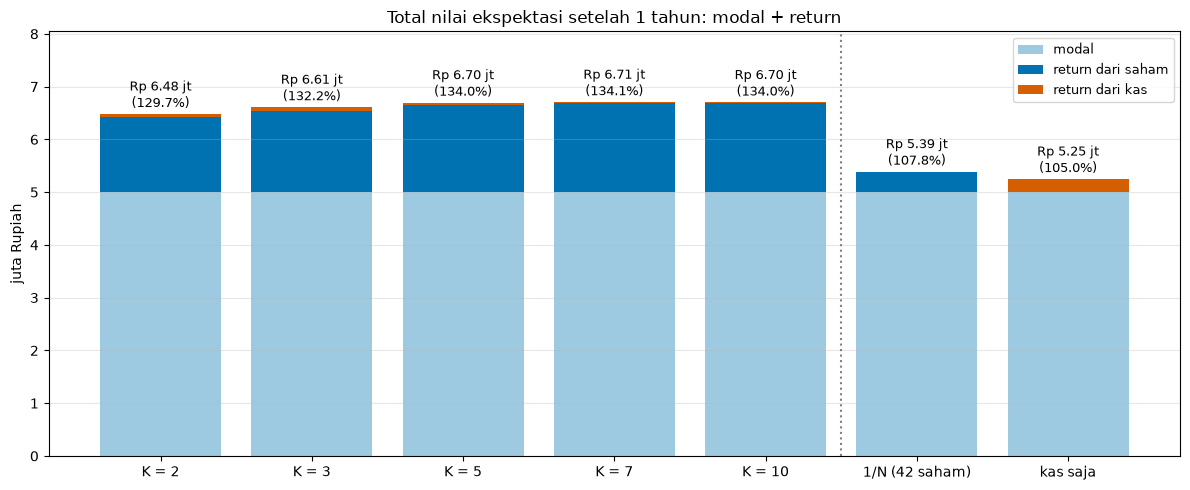

In [24]:
# ---- 11.5 total return ekspektasi (modal + return) per K ----
H6 = 126 / 252                                              # horizon 6 bulan (126 hari bursa), skala linear
nama_bar, modal_b, saham_b, kas_b = [], [], [], []
baris = []
for K in K_LIST:
    r_saham, r_kas = AN[K]["R_saham"].sum() * D, AN[K]["R_kas"] * D
    nama_bar.append(f"K = {K}"); modal_b.append(D); saham_b.append(r_saham); kas_b.append(r_kas)
    baris.append({"K": K, "modal": rp(D), "return dari saham": rp(r_saham), "return dari kas": rp(r_kas),
                  "total return / tahun": rp(r_saham + r_kas), "TOTAL 1 tahun (modal + return)": rp(D + r_saham + r_kas),
                  "% dari modal": f"{(D + r_saham + r_kas) / D:.1%}", "TOTAL 6 bulan": rp(D + (r_saham + r_kas) * H6)})
for nama, r_s, r_k in [("1/N (42 saham)", R_eq * D, 0.0), ("kas saja", 0.0, RF * D)]:
    nama_bar.append(nama); modal_b.append(D); saham_b.append(r_s); kas_b.append(r_k)
    baris.append({"K": nama, "modal": rp(D), "return dari saham": rp(r_s), "return dari kas": rp(r_k),
                  "total return / tahun": rp(r_s + r_k), "TOTAL 1 tahun (modal + return)": rp(D + r_s + r_k),
                  "% dari modal": f"{(D + r_s + r_k) / D:.1%}", "TOTAL 6 bulan": rp(D + (r_s + r_k) * H6)})
print(f"Total nilai ekspektasi (modal + return), modal {rp(D)}, {DATA_K}\n")
print(pd.DataFrame(baris).to_string(index=False))

fig, a_ = plt.subplots(figsize=(12, 5))
x_ = np.arange(len(nama_bar))
modal_b, saham_b, kas_b = np.array(modal_b) / 1e6, np.array(saham_b) / 1e6, np.array(kas_b) / 1e6
a_.bar(x_, modal_b, color="#9ecae1", label="modal")
a_.bar(x_, saham_b, bottom=modal_b, color=WARNA_LAYAK, label="return dari saham")
a_.bar(x_, kas_b, bottom=modal_b + saham_b, color=WARNA_LANGGAR, label="return dari kas")
for i in range(len(nama_bar)):
    total = modal_b[i] + saham_b[i] + kas_b[i]
    a_.text(i, total + 0.05, f"Rp {total:.2f} jt\n({total / (D / 1e6):.1%})", ha="center", va="bottom", fontsize=9)
a_.axvline(len(K_LIST) - 0.5, color="gray", ls=":")
a_.set_xticks(x_, nama_bar)
a_.set(title="Total nilai ekspektasi setelah 1 tahun: modal + return", ylabel="juta Rupiah", ylim=(0, (modal_b + saham_b + kas_b).max() * 1.2))
a_.legend(fontsize=9, loc="upper right"); a_.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

### 11.6 Hasil akhir: modal di saham + sisa kas + return

Hasil akhir menjumlahkan **semua bagian dana**: **modal yang dibelikan saham**, **sisa kas** (modal yang tidak menjadi saham karena
batas risiko, cap, atau pembulatan lot), dan **return** (dari saham dan dari kas). Jumlahnya sama dengan total pada 11.5, tetapi di
sini terlihat *di mana* uang itu berada.

$$\text{hasil akhir} = \underbrace{\sum_i n_i \cdot 100 P_i}_{\text{modal di saham}} + \underbrace{(D - \text{dana terpakai})}_{\text{sisa kas}}
+ \underbrace{D \sum_i w_i \mu_i}_{\text{return saham}} + \underbrace{D\, w_0 r_f}_{\text{return kas}}$$

Hasil akhir ekspektasi setelah 1 tahun: modal di saham + sisa kas + return (modal Rp 5.000.000, kasus_tetap)

             K modal di saham sisa kas (modal) return saham return kas  HASIL AKHIR % dari modal
             2   Rp 3.787.500     Rp 1.212.500 Rp 1.422.256  Rp 60.625 Rp 6.482.881       129.7%
             3   Rp 3.500.000     Rp 1.500.000 Rp 1.536.460  Rp 75.000 Rp 6.611.460       132.2%
             5   Rp 4.042.500       Rp 957.500 Rp 1.649.847  Rp 47.875 Rp 6.697.722       134.0%
             7   Rp 4.635.500       Rp 364.500 Rp 1.688.495  Rp 18.225 Rp 6.706.720       134.1%
            10   Rp 4.733.500       Rp 266.500 Rp 1.686.556  Rp 13.325 Rp 6.699.881       134.0%
1/N (42 saham)   Rp 5.000.000             Rp 0   Rp 390.099       Rp 0 Rp 5.390.099       107.8%
      kas saja           Rp 0     Rp 5.000.000         Rp 0 Rp 250.000 Rp 5.250.000       105.0%

Contoh K = 7: Rp 4.635.500 di saham + Rp 364.500 sisa kas + Rp 1.688.495 return saham + Rp 18.225 return kas = Rp

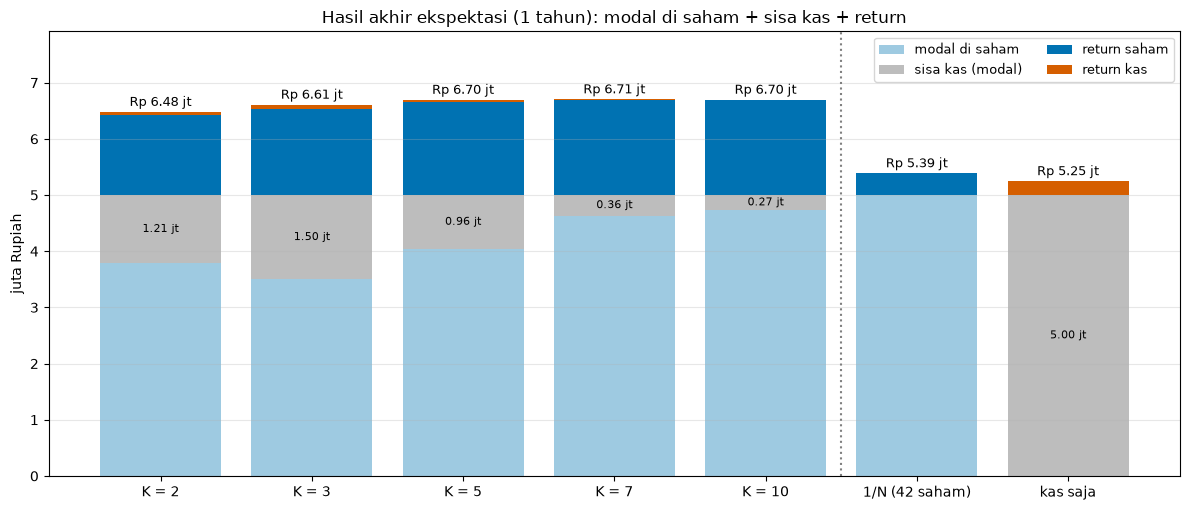

In [25]:
# ---- 11.6 hasil akhir ekspektasi: modal di saham + sisa kas + return ----
HA = {}
for K in K_LIST:
    P_, A_ = hasil_K[K][0], AN[K]
    di_saham = float((terbaik_K[K].lots * P_.harga_lot).sum())
    HA[K] = dict(saham=di_saham, kas=D - di_saham, r_saham=A_["R_saham"].sum() * D, r_kas=A_["R_kas"] * D)
HA["1/N (42 saham)"] = dict(saham=D, kas=0.0, r_saham=R_eq * D, r_kas=0.0)
HA["kas saja"] = dict(saham=0.0, kas=D, r_saham=0.0, r_kas=RF * D)
for h in HA.values():
    h["total"] = h["saham"] + h["kas"] + h["r_saham"] + h["r_kas"]
for K in K_LIST:                                               # harus sama dengan total pada 11.5
    assert abs(HA[K]["total"] - D * (1 + AN[K]["R"])) < 1e-6

baris = [{"K": nama, "modal di saham": rp(h["saham"]), "sisa kas (modal)": rp(h["kas"]), "return saham": rp(h["r_saham"]),
          "return kas": rp(h["r_kas"]), "HASIL AKHIR": rp(h["total"]), "% dari modal": f"{h['total'] / D:.1%}"} for nama, h in HA.items()]
print(f"Hasil akhir ekspektasi setelah 1 tahun: modal di saham + sisa kas + return (modal {rp(D)}, {DATA_K})\n")
print(pd.DataFrame(baris).to_string(index=False))
hb = HA[K_best]
print(f"\nContoh K = {K_best}: {rp(hb['saham'])} di saham + {rp(hb['kas'])} sisa kas + {rp(hb['r_saham'])} return saham + {rp(hb['r_kas'])} return kas"
      f" = {rp(hb['total'])}")

nama_h = [f"K = {k}" if isinstance(k, int) else k for k in HA]
seg = [("saham", "modal di saham", "#9ecae1"), ("kas", "sisa kas (modal)", "#bdbdbd"), ("r_saham", "return saham", WARNA_LAYAK), ("r_kas", "return kas", WARNA_LANGGAR)]
fig, a_ = plt.subplots(figsize=(12, 5.2))
x_ = np.arange(len(nama_h)); bawah = np.zeros(len(nama_h))
for kunci, label, warna in seg:
    nilai = np.array([h[kunci] for h in HA.values()]) / 1e6
    a_.bar(x_, nilai, bottom=bawah, color=warna, label=label)
    for i, v_ in enumerate(nilai):
        if kunci == "kas" and v_ > 0.25:
            a_.text(i, bawah[i] + v_ / 2, f"{v_:.2f} jt", ha="center", va="center", fontsize=8)
    bawah += nilai
for i, h in enumerate(HA.values()):
    a_.text(i, bawah[i] + 0.05, f"Rp {h['total'] / 1e6:.2f} jt", ha="center", va="bottom", fontsize=9)
a_.axvline(len(K_LIST) - 0.5, color="gray", ls=":")
a_.set_xticks(x_, nama_h)
a_.set(title="Hasil akhir ekspektasi (1 tahun): modal di saham + sisa kas + return", ylabel="juta Rupiah", ylim=(0, bawah.max() * 1.18))
a_.legend(fontsize=9, loc="upper right", ncol=2); a_.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

Data uji: 2025-10-01 s.d. 2026-09-30 (239 hari bursa), buat-dan-tahan tanpa rebalancing; modal Rp 5.000.000

    portofolio ekspektasi (latih) hasil nyata (uji, total)  nilai akhir     di saham       di kas untung/rugi setara / tahun vol nyata drawdown maks
         K = 2              29.7%                    -9.2% Rp 4.541.291 Rp 3.271.366 Rp 1.269.925 Rp -458.709          -9.7%     23.4%        -20.5%
         K = 3              32.2%                    +9.6% Rp 5.478.374 Rp 3.907.333 Rp 1.571.041  Rp 478.374         +10.1%     24.6%        -16.1%
         K = 5              34.0%                    +6.4% Rp 5.320.581 Rp 4.317.733 Rp 1.002.848  Rp 320.581          +6.8%     25.1%        -17.2%
         K = 7              34.1%                    +4.2% Rp 5.211.997 Rp 4.830.234   Rp 381.763  Rp 211.997          +4.5%     26.4%        -21.4%
        K = 10              34.0%                    +5.8% Rp 5.289.990 Rp 5.010.869   Rp 279.122  Rp 289.990          +6.1%     26.1%        -21.

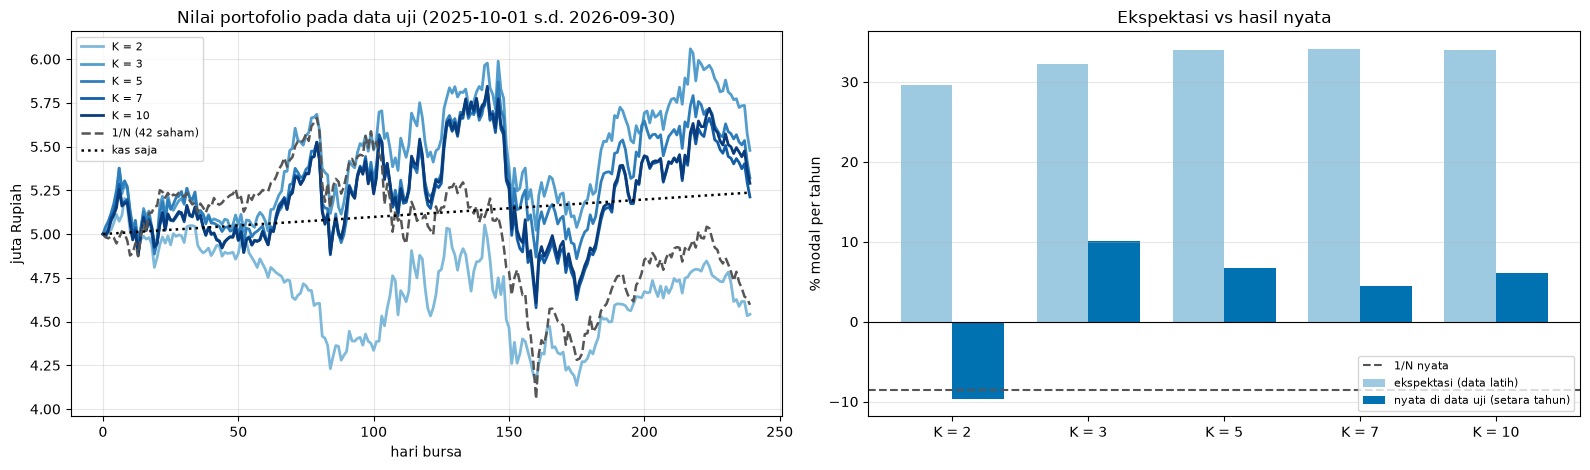

In [26]:
# ---- 11.7 uji pada data uji (TIDAK dipakai dalam optimasi): beli-dan-tahan portofolio hasil GA ----
r_uji = DATA[DATA_K]["return_uji"]                          # (T, N) return sederhana harian, urutan saham sama
T = len(r_uji)
t_uji = np.arange(1, T + 1)
tgl_awal, tgl_akhir = DATA[DATA_K]["tanggal_uji_awal"], DATA[DATA_K]["tanggal_uji_akhir"]


def nilai_uji(P, lots):
    # Nilai portofolio harian (Rp): tiap saham tumbuh sesuai return hariannya, kas tumbuh r_f.
    pos = lots * P.harga_lot
    saham = np.cumprod(1.0 + r_uji, axis=0) @ pos
    kas = (P.D - pos.sum()) * (1.0 + P.rf) ** (t_uji / 252)
    return saham + kas


def metrik_uji(nilai, D=D):
    harian = np.diff(np.concatenate([[D], nilai])) / np.concatenate([[D], nilai[:-1]])
    total = nilai[-1] / D - 1
    puncak = np.maximum.accumulate(np.concatenate([[D], nilai]))[1:]
    return dict(total=total, setara_tahun=total * 252 / T, vol=harian.std(ddof=1) * np.sqrt(252), mdd=float((nilai / puncak - 1).min()))


N_ = P0.n
V = {f"K = {K}": nilai_uji(hasil_K[K][0], terbaik_K[K].lots) for K in K_LIST}
V["1/N (42 saham)"] = (D / N_) * np.cumprod(1.0 + r_uji, axis=0).sum(1)
V["kas saja"] = D * (1.0 + RF) ** (t_uji / 252)
M = {nama: metrik_uji(v) for nama, v in V.items()}


def komponen_akhir(P, lots):
    # Nilai akhir yang berada di saham dan di kas (kas tumbuh r_f) pada akhir periode uji.
    pos = lots * P.harga_lot
    return float(np.cumprod(1.0 + r_uji, axis=0)[-1] @ pos), float((P.D - pos.sum()) * (1.0 + P.rf) ** (T / 252))


KA = {K: komponen_akhir(hasil_K[K][0], terbaik_K[K].lots) for K in K_LIST}
KA["1/N (42 saham)"] = (float(V["1/N (42 saham)"][-1]), 0.0)
KA["kas saja"] = (0.0, float(V["kas saja"][-1]))

print(f"Data uji: {tgl_awal} s.d. {tgl_akhir} ({T} hari bursa), buat-dan-tahan tanpa rebalancing; modal {rp(D)}\n")
baris = []
for K in K_LIST:
    m = M[f"K = {K}"]
    baris.append({"portofolio": f"K = {K}", "ekspektasi (latih)": f"{AN[K]['R']:.1%}", "hasil nyata (uji, total)": f"{m['total']:+.1%}",
                  "nilai akhir": rp(V[f'K = {K}'][-1]), "di saham": rp(KA[K][0]), "di kas": rp(KA[K][1]), "untung/rugi": rp(V[f'K = {K}'][-1] - D),
                  "setara / tahun": f"{m['setara_tahun']:+.1%}", "vol nyata": f"{m['vol']:.1%}", "drawdown maks": f"{m['mdd']:.1%}"})
for nama in ["1/N (42 saham)", "kas saja"]:
    m = M[nama]
    baris.append({"portofolio": nama, "ekspektasi (latih)": f"{R_eq:.1%}" if nama.startswith("1/N") else f"{RF:.1%}",
                  "hasil nyata (uji, total)": f"{m['total']:+.1%}", "nilai akhir": rp(V[nama][-1]), "di saham": rp(KA[nama][0]), "di kas": rp(KA[nama][1]), "untung/rugi": rp(V[nama][-1] - D),
                  "setara / tahun": f"{m['setara_tahun']:+.1%}", "vol nyata": f"{m['vol']:.1%}", "drawdown maks": f"{m['mdd']:.1%}"})
print(pd.DataFrame(baris).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
hari = np.arange(0, T + 1)
for K in K_LIST:
    ax[0].plot(hari, np.concatenate([[D], V[f"K = {K}"]]) / 1e6, color=warnaK[K], lw=2, label=f"K = {K}")
ax[0].plot(hari, np.concatenate([[D], V["1/N (42 saham)"]]) / 1e6, color="#555555", ls="--", lw=1.8, label="1/N (42 saham)")
ax[0].plot(hari, np.concatenate([[D], V["kas saja"]]) / 1e6, color="black", ls=":", lw=1.8, label="kas saja")
ax[0].set(title=f"Nilai portofolio pada data uji ({tgl_awal} s.d. {tgl_akhir})", xlabel="hari bursa", ylabel="juta Rupiah")
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
lebar = 0.38
xs = np.arange(len(K_LIST))
ax[1].bar(xs - lebar / 2, [AN[K]["R"] * 100 for K in K_LIST], lebar, color="#9ecae1", label="ekspektasi (data latih)")
ax[1].bar(xs + lebar / 2, [M[f"K = {K}"]["setara_tahun"] * 100 for K in K_LIST], lebar, color=WARNA_LAYAK, label="nyata di data uji (setara tahun)")
ax[1].axhline(M["1/N (42 saham)"]["setara_tahun"] * 100, color="#555555", ls="--", label="1/N nyata")
ax[1].axhline(0, color="black", lw=0.8)
ax[1].set_xticks(xs, [f"K = {K}" for K in K_LIST]); ax[1].set(title="Ekspektasi vs hasil nyata", ylabel="% modal per tahun")
ax[1].legend(fontsize=8); ax[1].grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## 12. Kesimpulan

Teks di bawah dihitung dari hasil notebook ini (angka berubah otomatis bila `DATA_K`, jumlah seed, atau parameter diubah).

In [27]:
from IPython.display import Markdown, display

Kb = K_best
Rmed = {K: float(np.median(Rlayak[K])) for K in K_LIST}
kas_med = {K: float(np.median(kas_rp[K])) for K in K_LIST}
m_best, m_eq, m_kas = M["K = %d" % Kb], M["1/N (42 saham)"], M["kas saja"]
v_best = V["K = %d" % Kb][-1]
daftar = ", ".join("%s (%.0f%%)" % (P.tickers[i], A["w"][i] * 100) for i in idx)
rmed_txt = ", ".join("K = %d: %.1f%%" % (K, Rmed[K] * 100) for K in K_LIST)
detik = np.mean([r.seconds for K in K_LIST for r in hasil_K[K][1]])

brute = ""
if DATA_K in BF:                                       # verifikasi brute force K = 2 dan peran kas
    R_bf, R_bf5 = BF[DATA_K]["kas bebas"][0], BF[DATA_K]["kas <= 5%"][0]
    ok2 = np.mean([(r.feasible and r.R >= R_bf * 0.99) for r in hasil_K[2][1]])
    exact2 = np.mean([(r.feasible and r.R >= R_bf - 1e-9) for r in hasil_K[2][1]])
    brute = ("* **Verifikasi:** pada K = 2 optimum sejati dihitung dengan brute force (R* = %.2f%%). GA menemukannya pada %.0f%% seed "
             "dan mencapai gap <= 1%% pada %.0f%% seed; GA tidak pernah melampaui optimum. Bila kas tidak boleh ditahan sengaja "
             "(kas <= 5%%), optimum turun menjadi %.2f%%, sehingga gen kas terbukti penting." % (R_bf * 100, exact2 * 100, ok2 * 100, R_bf5 * 100))

layak_semua = np.mean([r.feasible for K in K_LIST for r in hasil_K[K][1]])
if korel_pair < korel_semua - 0.05:
    kor_txt = "dan **saling tidak searah** (rata-rata korelasi pasangan %.2f dibanding %.2f untuk seluruh saham)" % (korel_pair, korel_semua)
else:
    kor_txt = ("sedangkan korelasi antar saham terpilih (%.2f) tidak jauh berbeda dari rata-rata seluruh saham (%.2f), sehingga faktor "
               "utamanya adalah return per unit risiko, bukan diversifikasi" % (korel_pair, korel_semua))
total_K = {K: M["K = %d" % K]["total"] for K in K_LIST}
K_uji = max(total_K, key=total_K.get)
n_kas = sum(total_K[K] > m_kas["total"] for K in K_LIST)
n_eq = sum(total_K[K] > m_eq["total"] for K in K_LIST)
uji_txt = ("Dari %d portofolio hasil GA, %d mengungguli kas saja dan %d mengungguli 1/N di data uji. Portofolio terbaik di data uji adalah "
           "K = %d (%+.1f%%)" % (len(K_LIST), n_kas, n_eq, K_uji, total_K[K_uji] * 100))
if K_uji != Kb:
    uji_txt += ", bukan K = %d yang terbaik di data latih: peringkat di data latih tidak bertahan di data uji" % Kb
uji_txt += "."
bandingkan_kas = "di bawah" if m_best["total"] < m_kas["total"] else "di atas"

catatan_k10 = ""
if Rmed[10] < Rmed[7] - 1e-4:
    catatan_k10 = (" Pada K = 10 GA **belum menemukan optimum**: R median-nya lebih rendah daripada K = 7 padahal ruang solusinya "
                   "memuat K = 7 (ruang pencarian jauh lebih besar).")

butir = [
    ("**1. Return maksimum yang dapat diharapkan.** Dengan modal %s, batas risiko sigma <= %.1f%% per tahun (1,5x risiko portofolio 1/N), "
     "lot 100 lembar, dan paling banyak K saham, return ekspektasi tertinggi yang ditemukan GA adalah **%.1f%% per tahun dari modal "
     "(sekitar %s per tahun)**, pada K = %d, sehingga total nilai (modal + return) setelah satu tahun sekitar **%s (%.1f%% dari modal)** (rincian: %s di saham + %s sisa kas + %s return). Itu %.1f poin persentase di atas menyimpan seluruh dana sebagai kas (%.0f%% = %s), dan di atas "
     "portofolio 1/N (%.1f%%) dengan risiko yang diizinkan %.1fx risiko 1/N. Ini adalah *ekspektasi dalam sampel* (dari data latih), "
     "bukan jaminan."
     % (rp(D), P.sigma_max * 100, A["R"] * 100, rp(A["R"] * D), Kb, rp(D * (1 + A["R"])), (1 + A["R"]) * 100,
        rp(HA[Kb]["saham"]), rp(HA[Kb]["kas"]), rp(HA[Kb]["r_saham"] + HA[Kb]["r_kas"]),
        (A["R"] - RF) * 100, RF * 100, rp(RF * D),
        R_eq * 100, P.sigma_max / sigma_eq)),
    ("**2. Saham yang dipilih dan alasannya.** Portofolio terbaik: %s, dengan sisa kas %s (%.1f%%). Saham-saham ini dipilih karena memberi "
     "**return per unit risiko yang tinggi** (rata-rata (mu - r_f)/sigma terbobot %.2f dibanding %.2f untuk seluruh saham), %s. Return besar "
     "lalu muat di dalam anggaran risiko. Saham dengan mu tertinggi tidak otomatis terpilih bila volatilitasnya menghabiskan anggaran risiko, "
     "1 lot-nya terlalu mahal, atau ia kalah dari kombinasi lain (lihat bagian 11)."
     % (daftar, rp(A["kas"] * D), A["kas"] * 100, rasio_pf, rasio.mean(), kor_txt)),
    ("**3. Pengaruh K.** R median GA per K: %s. Sisa kas median menyusut dari %s (K = 2) menjadi %s (K = 10), karena lebih banyak saham "
     "memungkinkan batas risiko dipenuhi tanpa menahan kas. Batas 20%% per saham hanya berlaku untuk K >= 7, sehingga K <= 5 dan K >= 7 "
     "tidak sepenuhnya sebanding.%s" % (rmed_txt, rp(kas_med[2]), rp(kas_med[10]), catatan_k10)),
    ("**4. Peran kas dan batas risiko.** Pada K kecil, batas risiko hanya bisa dipenuhi dengan menahan sebagian dana sebagai kas "
     "(volatilitas saham tunggal terkecil hampir sama dengan batas risiko portofolio). Karena itu kromosom 2N+1 dengan gen kas dibutuhkan, "
     "dan seluruh kendala lain (kardinalitas, cap 20%, lot bulat, dana <= modal) dijamin oleh dekoder."),
    ("**5. Kinerja GA.** %.0f%% run pada semua K menghasilkan solusi yang memenuhi batas risiko, dengan kardinalitas, cap, lot bulat, dan "
     "dana <= modal selalu terpenuhi oleh konstruksi; satu run (20.000 evaluasi) hanya sekitar %.1f detik.\n\n%s" % (layak_semua * 100, detik, brute)),
    ("**6. Bukti pada data uji (%s s.d. %s, %d hari bursa).** Portofolio K = %d yang diekspektasikan %.1f%% per tahun menghasilkan "
     "**%+.1f%% selama periode uji (%s; setara %+.1f%% per tahun)**, dibanding 1/N %+.1f%% dan kas saja %+.1f%%; artinya hasil nyata "
     "%s hasil menyimpan kas dan jauh di bawah ekspektasinya. %s Selisih besar antara ekspektasi dan hasil nyata wajar terjadi: mu "
     "diestimasi dari data historis yang bising, optimasi cenderung memilih saham yang kebetulan tinggi di data latih (estimation error), "
     "dan satu lintasan %d hari belum cukup untuk menyimpulkan keunggulan. **Return pada butir 1 adalah ekspektasi dalam sampel, bukan prediksi.**"
     % (tgl_awal, tgl_akhir, T, Kb, A["R"] * 100, m_best["total"] * 100, rp(v_best - D), m_best["setara_tahun"] * 100,
        m_eq["total"] * 100, m_kas["total"] * 100, bandingkan_kas, uji_txt, T)),
]
display(Markdown("\n\n".join(butir)))

**1. Return maksimum yang dapat diharapkan.** Dengan modal Rp 5.000.000, batas risiko sigma <= 23.9% per tahun (1,5x risiko portofolio 1/N), lot 100 lembar, dan paling banyak K saham, return ekspektasi tertinggi yang ditemukan GA adalah **34.1% per tahun dari modal (sekitar Rp 1.706.720 per tahun)**, pada K = 7, sehingga total nilai (modal + return) setelah satu tahun sekitar **Rp 6.706.720 (134.1% dari modal)** (rincian: Rp 4.635.500 di saham + Rp 364.500 sisa kas + Rp 1.706.720 return). Itu 29.1 poin persentase di atas menyimpan seluruh dana sebagai kas (5% = Rp 250.000), dan di atas portofolio 1/N (7.8%) dengan risiko yang diizinkan 1.5x risiko 1/N. Ini adalah *ekspektasi dalam sampel* (dari data latih), bukan jaminan.

**2. Saham yang dipilih dan alasannya.** Portofolio terbaik: MEDC (19%), BRPT (15%), ADRO (17%), ESSA (11%), AKRA (12%), AMRT (12%), MAPI (7%), dengan sisa kas Rp 364.500 (7.3%). Saham-saham ini dipilih karena memberi **return per unit risiko yang tinggi** (rata-rata (mu - r_f)/sigma terbobot 0.64 dibanding 0.07 untuk seluruh saham), sedangkan korelasi antar saham terpilih (0.13) tidak jauh berbeda dari rata-rata seluruh saham (0.16), sehingga faktor utamanya adalah return per unit risiko, bukan diversifikasi. Return besar lalu muat di dalam anggaran risiko. Saham dengan mu tertinggi tidak otomatis terpilih bila volatilitasnya menghabiskan anggaran risiko, 1 lot-nya terlalu mahal, atau ia kalah dari kombinasi lain (lihat bagian 11).

**3. Pengaruh K.** R median GA per K: K = 2: 29.6%, K = 3: 30.1%, K = 5: 33.3%, K = 7: 33.7%, K = 10: 31.6%. Sisa kas median menyusut dari Rp 1.913.000 (K = 2) menjadi Rp 224.750 (K = 10), karena lebih banyak saham memungkinkan batas risiko dipenuhi tanpa menahan kas. Batas 20% per saham hanya berlaku untuk K >= 7, sehingga K <= 5 dan K >= 7 tidak sepenuhnya sebanding. Pada K = 10 GA **belum menemukan optimum**: R median-nya lebih rendah daripada K = 7 padahal ruang solusinya memuat K = 7 (ruang pencarian jauh lebih besar).

**4. Peran kas dan batas risiko.** Pada K kecil, batas risiko hanya bisa dipenuhi dengan menahan sebagian dana sebagai kas (volatilitas saham tunggal terkecil hampir sama dengan batas risiko portofolio). Karena itu kromosom 2N+1 dengan gen kas dibutuhkan, dan seluruh kendala lain (kardinalitas, cap 20%, lot bulat, dana <= modal) dijamin oleh dekoder.

**5. Kinerja GA.** 100% run pada semua K menghasilkan solusi yang memenuhi batas risiko, dengan kardinalitas, cap, lot bulat, dan dana <= modal selalu terpenuhi oleh konstruksi; satu run (20.000 evaluasi) hanya sekitar 0.2 detik.

* **Verifikasi:** pada K = 2 optimum sejati dihitung dengan brute force (R* = 29.66%). GA menemukannya pada 37% seed dan mencapai gap <= 1% pada 73% seed; GA tidak pernah melampaui optimum. Bila kas tidak boleh ditahan sengaja (kas <= 5%), optimum turun menjadi 21.15%, sehingga gen kas terbukti penting.

**6. Bukti pada data uji (2025-10-01 s.d. 2026-09-30, 239 hari bursa).** Portofolio K = 7 yang diekspektasikan 34.1% per tahun menghasilkan **+4.2% selama periode uji (Rp 211.997; setara +4.5% per tahun)**, dibanding 1/N -8.1% dan kas saja +4.7%; artinya hasil nyata di bawah hasil menyimpan kas dan jauh di bawah ekspektasinya. Dari 5 portofolio hasil GA, 3 mengungguli kas saja dan 4 mengungguli 1/N di data uji. Portofolio terbaik di data uji adalah K = 3 (+9.6%), bukan K = 7 yang terbaik di data latih: peringkat di data latih tidak bertahan di data uji. Selisih besar antara ekspektasi dan hasil nyata wajar terjadi: mu diestimasi dari data historis yang bising, optimasi cenderung memilih saham yang kebetulan tinggi di data latih (estimation error), dan satu lintasan 239 hari belum cukup untuk menyimpulkan keunggulan. **Return pada butir 1 adalah ekspektasi dalam sampel, bukan prediksi.**

**Keterbatasan:** estimasi μ sangat bising; universe adalah konstituen LQ45 saat ini (bias penyintas); biaya transaksi,
pajak, dan rebalancing tidak dimodelkan; Close Yahoo sudah disesuaikan split (lot pada jendela lama untuk saham yang split
sesudahnya tampak lebih murah); kas bernilai $r_f$ konstan; hasil uji hanya satu lintasan per jendela.

**Langkah berikut (sesuai rencana):**

1. Memindahkan kode yang sudah teruji ke modul `src/` (`problem.py`, `decoder.py`, `fitness.py`, `algorithms/ga.py`)
   dan tes pytest, supaya dipakai bersama SA, PSO, DE.
2. Solver eksak SCIP dan baseline (greedy forward, top-K + QP, acak valid) untuk mengukur gap pada K = 7 dan 10.
3. Fase 1 (penalaan: populasi, laju mutasi, `p_swap`, `n_seed`) dan Fase 2 (30 masalah × 30 seed), lalu uji statistik.